# Сравнение CTC и Whisper, диаризация и overlapping speech

Ноутбук реализует воспроизводимый конвейер обработки реальной многоговорящей записи:

1. подготовка аудио (16 kHz, mono) и ground truth;
2. распознавание речи двумя способами: `faster-whisper` и CTC (`wav2vec2`);
3. диаризация `pyannote.audio` (exclusive) и слияние с транскриптом;
4. детекция наложений и speech separation только на overlap-участках;
5. метрики WER/CER/DER/RTF и таблицы/графики.

**Данные:** реальная встреча AMI `ES2004a` (английский язык, 4 спикера, ~17.5 мин, реальные наложения), окно 0–600 с.
**Ground truth (эталон):** RTTM (кто когда говорил) и word-level транскрипт из ручной разметки AMI. Именно с ними сравниваются предсказания, поэтому WER/CER/DER — настоящие, а не «на глаз».

**Лицензия:** AMI Meeting Corpus, CC BY 4.0. Ссылки на источники — в ячейке загрузки.

**Ожидаемое время на GTX 1650 (4 GB):** 8–15 минут после установки моделей. Модели скачиваются один раз в `D:\speech_cache`.


## 0. Окружение и ограничения

- Python 3.11, `torch 2.13+cu130`, `jupyter_env`.
- На GTX 1650 всего 4 GB VRAM, поэтому модели загружаются последовательно, а separation выполняется на CPU.
- `ffmpeg` в PATH нет; WAV читается через `soundfile`, поэтому вход должен быть WAV/FLAC/OGG. Для mp3/m4a используйте `imageio-ffmpeg`.
- Все тяжёлые кэши (`HF_HOME`, `TORCH_HOME`, `PIP_CACHE_DIR`) перенаправляются на D:, потому что на C: свободно около 6 GB.


In [1]:
import os, sys, json, re, gc, time, math, random, getpass, hashlib, zipfile, shutil, urllib.request, warnings, difflib
from pathlib import Path
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

CACHE = Path(r"D:\speech_cache")
for sub in ("hf", "torch", "pip", "models"):
    (CACHE / sub).mkdir(parents=True, exist_ok=True)
os.environ.setdefault("HF_HOME", str(CACHE / "hf"))
os.environ.setdefault("TORCH_HOME", str(CACHE / "torch"))
os.environ.setdefault("PIP_CACHE_DIR", str(CACHE / "pip"))

BASE = Path.cwd()
DATA = BASE / "data" / "speech_pipeline"
OUT = BASE / "outputs" / "ami_es2004a_10min"
for p in (DATA, OUT):
    p.mkdir(parents=True, exist_ok=True)

MEETING = "ES2004a"
WINDOW = (0.0, 600.0)
LANGUAGE = "en"
NUM_SPEAKERS = 4
WHISPER_MODEL_NAME = "large-v3-turbo"
CTC_MODEL_NAME = "facebook/wav2vec2-large-960h-lv60-self"
SEPARATION_MODE = "demo"   # demo | auto | off
DEVICE = "cuda"
SEP_DEVICE = "cpu"

import torch
if not torch.cuda.is_available():
    DEVICE = "cpu"
print("torch:", torch.__version__)
print("device:", DEVICE)
if DEVICE == "cuda":
    print("gpu:", torch.cuda.get_device_name(0))
    free, total = torch.cuda.mem_get_info()
    print(f"VRAM free/total: {free / 2**30:.2f} / {total / 2**30:.2f} GiB")
try:
    drive = (CACHE.drive + "\\") if CACHE.drive else str(CACHE)
    du = shutil.disk_usage(drive)
    print(f"disk {drive}: free {du.free / 2**30:.1f} GiB")
except Exception as e:
    print("disk check skipped:", e)
print("DATA:", DATA)
print("OUT :", OUT)


torch: 2.13.0+cu130
device: cuda
gpu: NVIDIA GeForce GTX 1650
VRAM free/total: 3.22 / 4.00 GiB
disk D:\: free 112.5 GiB
DATA: c:\Users\Lenovo\OneDrive\Документы\Data Science\homeworks\data\speech_pipeline
OUT : c:\Users\Lenovo\OneDrive\Документы\Data Science\homeworks\outputs\ami_es2004a_10min


## 1. Hugging Face token (только для pyannote)



In [2]:
HF_TOKEN = os.environ.get("HF_TOKEN", "").strip()
if not HF_TOKEN:
    try:
        HF_TOKEN = getpass.getpass("HF token (hf_...): ").strip()
    except Exception:
        HF_TOKEN = ""
if HF_TOKEN:
    os.environ["HF_TOKEN"] = HF_TOKEN

HF_OK = False
if HF_TOKEN:
    try:
        from huggingface_hub import HfApi, model_info
        me = HfApi(token=HF_TOKEN).whoami()
        print("HF user:", me.get("name"))
        for mid in ("pyannote/speaker-diarization-community-1",):
            try:
                model_info(mid, token=HF_TOKEN)
                print("OK  ", mid)
            except Exception as e:
                print("FAIL", mid, type(e).__name__, str(e)[:200])
        HF_OK = True
    except Exception as e:
        print("HF token check failed:", type(e).__name__, e)
else:
    print("HF token не задан: диаризация и детекция наложений будут пропущены.")


HF user: Saveliy15
OK   pyannote/speaker-diarization-community-1


## 2. Загрузка реального аудио AMI и эталонной разметки

Скачиваются три файла: аудио встречи (32 MB), RTTM-эталон диаризации и архив ручных аннотаций AMI (21.8 MB). Повторный запуск использует уже скачанные файлы.


In [3]:
AMI_AUDIO_URL = "http://groups.inf.ed.ac.uk/ami/AMICorpusMirror/amicorpus/ES2004a/audio/ES2004a.Mix-Headset.wav"
AMI_RTTM_URL = "https://raw.githubusercontent.com/pyannote/AMI-diarization-setup/main/only_words/rttms/test/ES2004a.rttm"
AMI_ANN_URL = "https://groups.inf.ed.ac.uk/ami/AMICorpusAnnotations/ami_public_manual_1.6.2.zip"

def download(url, dst, chunk=1 << 20):
    dst = Path(dst)
    if dst.exists() and dst.stat().st_size > 0:
        print("exists:", dst.name, f"{dst.stat().st_size / 2**20:.1f} MB")
        return dst
    dst.parent.mkdir(parents=True, exist_ok=True)
    tmp = dst.with_name(dst.name + ".part")
    with urllib.request.urlopen(url, timeout=90) as r, open(tmp, "wb") as f:
        total = int(r.headers.get("Content-Length", 0))
        done = 0
        while True:
            block = r.read(chunk)
            if not block:
                break
            f.write(block)
            done += len(block)
            if total and done % (10 * chunk) < chunk:
                print(f"  {dst.name}: {done / 2**20:.1f}/{total / 2**20:.1f} MB")
    tmp.replace(dst)
    print("downloaded:", dst.name, f"{dst.stat().st_size / 2**20:.1f} MB")
    return dst

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()

AUDIO_SRC = download(AMI_AUDIO_URL, DATA / "raw" / f"{MEETING}.Mix-Headset.wav")
RTTM_SRC = download(AMI_RTTM_URL, DATA / "raw" / f"{MEETING}.rttm")
ANN_ZIP = download(AMI_ANN_URL, DATA / "raw" / "ami_public_manual_1.6.2.zip")

ANN_ROOT = DATA / "annotations"
if not (ANN_ROOT / "words").exists():
    ANN_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ANN_ZIP) as z:
        z.extractall(ANN_ROOT)
    nested = sorted(ANN_ROOT.glob("ami_public_manual*"))
    if nested and (nested[0] / "words").exists():
        ANN_ROOT = nested[0]
print("annotations:", ANN_ROOT)
print("word files:", len(list((ANN_ROOT / "words").glob(f"{MEETING}.*.words.xml"))))

manifest = {p.name: {"path": str(p), "bytes": p.stat().st_size, "sha256": sha256(p)}
            for p in (AUDIO_SRC, RTTM_SRC, ANN_ZIP)}
(DATA / "downloads.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")


exists: ES2004a.Mix-Headset.wav 32.0 MB
exists: ES2004a.rttm 0.0 MB
exists: ami_public_manual_1.6.2.zip 21.8 MB
annotations: c:\Users\Lenovo\OneDrive\Документы\Data Science\homeworks\data\speech_pipeline\annotations
word files: 4


936

## 3. Ground truth: обрезка окна, RTTM и word-level транскрипт

- Аудио обрезается до `WINDOW` (0–600 с), RTTM — тем же окном.
- Из `words/*.xml` извлекаются слова с таймкодами и глобальными именами спикеров (`FEE013` и т.д.).
- Слова склеиваются в реплики; отдельно сохраняются word-level и turn-level эталоны в JSONL.
- Наложения считаются по RTTM: интервалы, где одновременно активны 2+ спикера.


In [4]:
import soundfile as sf
import xml.etree.ElementTree as ET
try:
    import soxr
except Exception:
    soxr = None

def resample(x, sr_in, sr_out):
    x = np.asarray(x, dtype=np.float32)
    if sr_in == sr_out:
        return x
    if soxr is not None:
        return soxr.resample(x, sr_in, sr_out).astype(np.float32)
    import torch, torchaudio
    t = torch.from_numpy(x)
    return torchaudio.functional.resample(t, sr_in, sr_out).numpy()

def clip_audio(src, dst, start=0.0, end=600.0, sr=16000):
    x, sr_in = sf.read(str(src), always_2d=True, dtype="float32")
    x = x.mean(axis=1)
    x = resample(x, sr_in, sr)
    x = x[int(start * sr):int(end * sr)]
    sf.write(str(dst), x, sr, subtype="PCM_16")
    return dst

def read_rttm(path):
    turns = []
    for line in Path(path).read_text(encoding="utf-8").splitlines():
        p = line.split()
        if len(p) < 8 or p[0] != "SPEAKER":
            continue
        turns.append({"start": float(p[3]), "end": float(p[3]) + float(p[4]), "speaker": p[7]})
    return sorted(turns, key=lambda t: (t["start"], t["end"]))

def write_rttm(turns, path, uri=MEETING):
    with open(path, "w", encoding="utf-8") as f:
        for t in sorted(turns, key=lambda x: (x["start"], x["speaker"])):
            d = t["end"] - t["start"]
            if d > 0:
                f.write(f"SPEAKER {uri} 1 {t['start']:.3f} {d:.3f} <NA> <NA> {t['speaker']} <NA> <NA>\n")

def write_jsonl(rows, path):
    with open(path, "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

def clip_turns(turns, start, end):
    out = []
    for t in turns:
        s, e = max(t["start"], start), min(t["end"], end)
        if e - s > 0.05:
            out.append({"start": s, "end": e, "speaker": t["speaker"]})
    return sorted(out, key=lambda x: (x["start"], x["end"]))

WAV_10MIN = DATA / f"{MEETING}_10min.wav"
RTTM_10MIN = DATA / f"{MEETING}_10min.rttm"
clip_audio(AUDIO_SRC, WAV_10MIN, *WINDOW)
TURNS_GT = clip_turns(read_rttm(RTTM_SRC), *WINDOW)
write_rttm(TURNS_GT, RTTM_10MIN)
AUDIO_DURATION = sf.info(str(WAV_10MIN)).duration
print("wav:", WAV_10MIN, f"{AUDIO_DURATION:.2f} sec")
print("gt turns:", len(TURNS_GT), "speakers:", sorted({t["speaker"] for t in TURNS_GT}))

def load_ami_words(ann_root, meeting=MEETING):
    names = {}
    for m in ET.parse(ann_root / "corpusResources" / "meetings.xml").getroot():
        if str(m.attrib.get("observation", "")).lower() != meeting.lower():
            continue
        for sp in list(m):
            names[sp.attrib.get("nxt_agent")] = sp.attrib.get("global_name", sp.attrib.get("nxt_agent"))
    xmls = sorted(set((ann_root / "words").glob(f"{meeting}.*.words.xml")) |
                  set((ann_root / "words").glob(f"{meeting.lower()}.*.words.xml")))
    words = []
    for xml in xmls:
        agent = xml.name.split(".")[1]
        spk = names.get(agent, agent)
        for el in ET.parse(xml).getroot().iter():
            if not str(el.tag).lower().endswith("w"):
                continue
            text = (el.text or "").strip()
            if not text or not re.search(r"[A-Za-z0-9']", text):
                continue
            words.append({"start": float(el.attrib["starttime"]),
                          "end": float(el.attrib["endtime"]),
                          "word": text, "speaker": spk})
    return sorted(words, key=lambda w: (w["start"], w["end"]))

WORDS_GT = load_ami_words(ANN_ROOT)
WORDS_GT = [w for w in WORDS_GT if w["end"] > WINDOW[0] and w["start"] < WINDOW[1]]
for w in WORDS_GT:
    w["start"] = max(w["start"], WINDOW[0])
    w["end"] = min(w["end"], WINDOW[1])
print("gt words:", len(WORDS_GT), "xml speakers:", sorted({w["speaker"] for w in WORDS_GT}))
if {w["speaker"] for w in WORDS_GT} != {t["speaker"] for t in TURNS_GT}:
    print("WARNING: speaker sets in RTTM and words XML differ; проверьте mapping.")

def words_to_turns(words, max_gap=0.8):
    turns = []
    by = defaultdict(list)
    for w in words:
        by[w["speaker"]].append(w)
    for spk, ws in by.items():
        ws = sorted(ws, key=lambda x: x["start"])
        cur = None
        for w in ws:
            if cur and w["start"] - cur["end"] <= max_gap:
                cur["end"] = max(cur["end"], w["end"])
                cur["text"].append(w["word"])
            else:
                if cur:
                    turns.append(cur)
                cur = {"start": w["start"], "end": w["end"], "speaker": spk, "text": [w["word"]]}
        if cur:
            turns.append(cur)
    for t in turns:
        t["text"] = " ".join(t["text"])
    return sorted(turns, key=lambda x: x["start"])

GT_TURNS = words_to_turns(WORDS_GT)

def intervals_with_overlap(turns, step=0.01):
    if not turns:
        return [], np.zeros(0, dtype=np.int16)
    end = max(t["end"] for t in turns)
    n = max(1, int(np.ceil(end / step)))
    counts = np.zeros(n, dtype=np.int16)
    for t in turns:
        i0 = max(0, int(t["start"] / step))
        i1 = min(n, int(np.ceil(t["end"] / step)))
        counts[i0:i1] += 1
    mask = counts >= 2
    iv, start = [], None
    for i, m in enumerate(mask):
        if m and start is None:
            start = i
        if not m and start is not None:
            iv.append((start * step, i * step))
            start = None
    if start is not None:
        iv.append((start * step, len(mask) * step))
    return iv, counts

OVERLAP_IV_GT, COUNTS_GT = intervals_with_overlap(TURNS_GT)
OVERLAP_SEC_GT = sum(e - s for s, e in OVERLAP_IV_GT)
GT_SPEECH_SEC = sum(t["end"] - t["start"] for t in TURNS_GT)
OVERLAP_RATIO_GT = OVERLAP_SEC_GT / max(GT_SPEECH_SEC, 1e-9)
MAX_CONCURRENT_GT = int(COUNTS_GT.max()) if len(COUNTS_GT) else 0

GT_SUMMARY = {
    "meeting": MEETING, "window": WINDOW, "duration_sec": AUDIO_DURATION,
    "speakers_gt": sorted({t["speaker"] for t in TURNS_GT}),
    "gt_turns": len(GT_TURNS), "gt_words": len(WORDS_GT),
    "speech_sec": GT_SPEECH_SEC, "overlap_sec": OVERLAP_SEC_GT,
    "overlap_ratio": OVERLAP_RATIO_GT, "max_concurrent_speakers": MAX_CONCURRENT_GT,
    "overlap_intervals": OVERLAP_IV_GT,
}
(DATA / "gt_summary.json").write_text(json.dumps(GT_SUMMARY, indent=2, ensure_ascii=False), encoding="utf-8")
write_jsonl(WORDS_GT, DATA / "gt_words.jsonl")
write_jsonl(GT_TURNS, DATA / "gt_turns.jsonl")
print(f"overlap: {OVERLAP_SEC_GT:.1f} sec ({100 * OVERLAP_RATIO_GT:.1f}% of speech), "
      f"max concurrent = {MAX_CONCURRENT_GT}, intervals = {len(OVERLAP_IV_GT)}")
print("first GT turns:")
for t in GT_TURNS[:3]:
    print(f"  {t['start']:.2f}-{t['end']:.2f} {t['speaker']}: {t['text'][:80]}")


wav: c:\Users\Lenovo\OneDrive\Документы\Data Science\homeworks\data\speech_pipeline\ES2004a_10min.wav 600.00 sec
gt turns: 122 speakers: ['FEE013', 'FEE016', 'MEE014', 'MEO015']
gt words: 1107 xml speakers: ['FEE013', 'FEE016', 'MEE014', 'MEO015']
overlap: 52.8 sec (12.6% of speech), max concurrent = 4, intervals = 47
first GT turns:
  0.37-1.76 MEO015: Hmm hmm hmm
  10.99-14.53 FEE013: Are we we're not allowed to dim the lights so people can see that a bit better
  17.88-18.15 MEO015: Yeah


## 4. Метрики

- **WER/CER** — `jiwer` после нормализации (lowercase, пунктуация удаляется).
- **DER** — `pyannote.metrics` с collar 0.25 с; отдельно считается DER с `skip_overlap=True`.
- **RTF** — отношение времени инференса к длительности аудио.
- **Overlap recovery** — доля эталонных слов внутри наложений, найденных с правильным спикером (приближённая метрика на основе выравнивания последовательностей).
- **SA-WER** — WER по каждому спикеру после слияния ASR и диаризации.


In [5]:
def norm_text(s):
    s = (s or "").lower().replace("’", "'")
    s = re.sub(r"\[[^\]]*\]", " ", s)
    s = re.sub(r"<[^>]*>", " ", s)
    s = re.sub(r"[^a-z0-9'\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

def wer_cer(ref, hyp):
    try:
        import jiwer
    except Exception as e:
        raise RuntimeError("Установите jiwer: python -m pip install jiwer") from e
    r, h = norm_text(ref), norm_text(hyp)
    if not r:
        return {"wer": None, "cer": None, "ref_words": 0, "hyp_words": len(h.split())}
    return {"wer": float(jiwer.wer(r, h)), "cer": float(jiwer.cer(r, h)),
            "ref_words": len(r.split()), "hyp_words": len(h.split())}

class Timer:
    def __init__(self, name, device=None):
        self.name = name
        self.device = device or DEVICE
        self.elapsed = None
    def __enter__(self):
        if self.device == "cuda" and torch.cuda.is_available():
            torch.cuda.synchronize()
        self.t0 = time.perf_counter()
        return self
    def __exit__(self, *args):
        if self.device == "cuda" and torch.cuda.is_available():
            torch.cuda.synchronize()
        self.elapsed = time.perf_counter() - self.t0

def turns_to_annotation(turns, uri=MEETING):
    from pyannote.core import Annotation, Segment
    ann = Annotation(uri=uri)
    for t in turns:
        seg = Segment(float(t["start"]), float(t["end"]))
        ann[seg, str(t["speaker"])] = str(t["speaker"])
    return ann

def annotation_to_turns(ann):
    return [{"start": float(turn.start), "end": float(turn.end), "speaker": str(spk)}
            for turn, _, spk in ann.itertracks(yield_label=True)]

def to_exclusive(annotation, step=0.01):
    from pyannote.core import Annotation, Segment
    if annotation.get_timeline().duration() <= 0:
        return Annotation(uri=annotation.uri)
    extent = annotation.get_timeline().extent()
    n = max(1, int(np.ceil(extent.duration / step)))
    labels = np.full(n, "", dtype=object)
    turns = sorted(annotation.itertracks(yield_label=True), key=lambda x: -x[0].duration)
    for turn, _, spk in turns:
        i0 = max(0, int((turn.start - extent.start) / step))
        i1 = min(n, int(np.ceil((turn.end - extent.start) / step)))
        if i1 <= i0:
            continue
        sub = labels[i0:i1]
        sub[sub == ""] = str(spk)
    out = Annotation(uri=annotation.uri)
    if n == 0:
        return out
    start, cur = 0, labels[0]
    for i in range(1, n + 1):
        if i == n or labels[i] != cur:
            if cur != "":
                a = extent.start + start * step
                b = min(extent.start + i * step, extent.end)
                if b - a > 0:
                    out[Segment(a, b), str(cur)] = str(cur)
            if i < n:
                start, cur = i, labels[i]
    return out

def compute_der(ref_turns, hyp_turns):
    try:
        from pyannote.metrics.diarization import DiarizationErrorRate
    except Exception as e:
        return {"error": f"pyannote.metrics недоступен: {type(e).__name__}: {e}"}
    ref = turns_to_annotation(ref_turns)
    hyp = turns_to_annotation(hyp_turns)
    der = DiarizationErrorRate(collar=0.25, skip_overlap=False)
    overall = der(ref, hyp)
    try:
        detail = der(ref, hyp, detailed=True)
        components = {str(k): float(v) for k, v in detail.items()
                      if isinstance(v, (int, float, np.integer, np.floating))}
    except Exception:
        components = {}
    der_skip = DiarizationErrorRate(collar=0.25, skip_overlap=True)(ref, hyp)
    return {"der": float(overall), "der_skip_overlap": float(der_skip), "components": components}

def speaker_overlap_matrix(ref_turns, hyp_turns):
    rs = sorted({t["speaker"] for t in ref_turns})
    hs = sorted({t["speaker"] for t in hyp_turns})
    m = np.zeros((len(rs), len(hs)), dtype=np.float64)
    for r in ref_turns:
        for h in hyp_turns:
            d = max(0.0, min(r["end"], h["end"]) - max(r["start"], h["start"]))
            if d > 0:
                m[rs.index(r["speaker"]), hs.index(h["speaker"])] += d
    return rs, hs, m

def map_speakers(ref_turns, hyp_turns):
    if not ref_turns or not hyp_turns:
        return {}, 0.0
    from scipy.optimize import linear_sum_assignment
    rs, hs, m = speaker_overlap_matrix(ref_turns, hyp_turns)
    rows, cols = linear_sum_assignment(-m)
    mapping = {hs[c]: rs[r] for r, c in zip(rows, cols)}
    total = m.sum()
    score = float(m[rows, cols].sum() / total) if total > 0 else 0.0
    return mapping, score

def mask_to_intervals(mask, step, min_dur=0.25, offset=0.0):
    iv, start = [], None
    for i, m in enumerate(mask):
        if m and start is None:
            start = i
        if not m and start is not None:
            a, b = offset + start * step, offset + i * step
            if b - a >= min_dur:
                iv.append((a, b))
            start = None
    if start is not None:
        a, b = offset + start * step, offset + len(mask) * step
        if b - a >= min_dur:
            iv.append((a, b))
    return iv

def interval_intersection_sec(a_iv, b_iv):
    total = 0.0
    for a0, a1 in a_iv:
        for b0, b1 in b_iv:
            total += max(0.0, min(a1, b1) - max(a0, b0))
    return total

def overlap_recovery(gt_words, hyp_words, overlap_iv, tol=1.5):
    def inside(w):
        mid = 0.5 * (w["start"] + w["end"])
        return any(a <= mid <= b for a, b in overlap_iv)
    ref = [w for w in gt_words if inside(w)]
    hyp = [w for w in hyp_words if inside(w)]
    if not ref:
        return {"ref_overlap_words": 0, "hyp_overlap_words": len(hyp), "matched": 0,
                "time_correct": 0, "speaker_correct": 0, "recall": None, "speaker_accuracy": None}
    sm = difflib.SequenceMatcher(a=[norm_text(w["word"]) for w in ref],
                                 b=[norm_text(w["word"]) for w in hyp], autojunk=False)
    matched = correct = time_ok = 0
    for blk in sm.get_matching_blocks():
        for k in range(blk.size):
            r, h = ref[blk.a + k], hyp[blk.b + k]
            matched += 1
            if abs(r["start"] - h["start"]) <= tol:
                time_ok += 1
            if r["speaker"] == h["speaker"]:
                correct += 1
    return {"ref_overlap_words": len(ref), "hyp_overlap_words": len(hyp),
            "matched": matched, "time_correct": time_ok, "speaker_correct": correct,
            "recall": matched / len(ref), "speaker_accuracy": correct / max(matched, 1)}

def speaker_wer(gt_words, hyp_words):
    by_ref, by_hyp = defaultdict(list), defaultdict(list)
    for w in gt_words:
        by_ref[w["speaker"]].append(w)
    for w in hyp_words:
        by_hyp[w["speaker"]].append(w)
    out = {}
    for spk in sorted(by_ref):
        r = " ".join(w["word"] for w in sorted(by_ref[spk], key=lambda x: x["start"]))
        h = " ".join(w["word"] for w in sorted(by_hyp.get(spk, []), key=lambda x: x["start"]))
        if r.strip():
            out[spk] = wer_cer(r, h)
    return out

print("metrics helpers ready")


metrics helpers ready


## 5. Диаризация спикеров

Используется `pyannote/speaker-diarization-community-1` (fallback — `speaker-diarization-3.1`), `num_speakers=4`.
Нужны две разметки:

- **full** — с наложениями (для оценки overlap и `max_concurrent`);
- **exclusive** — каждый момент принадлежит одному спикеру (для слияния с ASR и DER).

Спикеры hyp сопоставляются с именами AMI через матрицу пересечений; это стандартное выравнивание меток, оно не влияет на DER.

Аудио подаётся в pyannote in-memory (`{"waveform": tensor, "sample_rate": sr}`), поэтому системный FFmpeg/torchcodec для декодирования не требуется.


In [6]:
DIAR_OK = False
TURNS_HYP_FULL, TURNS_HYP_EXCL = [], []
HYP2REF, HYP2REF_SCORE = {}, 0.0
DIAR_METRICS = {}
DIAR_TIMING = {}

if not HF_OK:
    print("SKIP diarization: нет HF token.")
else:
    pipe = None
    try:
        from pyannote.audio import Pipeline

        def load_pipe(model_id):
            try:
                return Pipeline.from_pretrained(model_id, token=HF_TOKEN)
            except TypeError:
                return Pipeline.from_pretrained(model_id, use_auth_token=HF_TOKEN)

        for model_id in ("pyannote/speaker-diarization-community-1",
                         "pyannote/speaker-diarization-3.1"):
            try:
                pipe = load_pipe(model_id)
                print("loaded:", model_id)
                break
            except Exception as e:
                print("cannot load", model_id, type(e).__name__, str(e)[:200])
        if pipe is None:
            raise RuntimeError("ни одна модель диаризации не загрузилась")

        pipe.to(torch.device(DEVICE))
        x_diar, sr_diar = sf.read(str(WAV_10MIN), dtype="float32")
        if x_diar.ndim > 1:
            x_diar = x_diar.mean(axis=1)
        waveform = torch.from_numpy(np.ascontiguousarray(x_diar)).unsqueeze(0)
        audio_in = {"waveform": waveform, "sample_rate": int(sr_diar)}
        print("diarization input: in-memory waveform", tuple(waveform.shape), "sr", sr_diar)
        try:
            with Timer("diarization", device=DEVICE) as tm:
                output = pipe(audio_in, num_speakers=NUM_SPEAKERS)
        except RuntimeError as e:
            if "out of memory" in str(e).lower() and DEVICE == "cuda":
                print("CUDA OOM: повтор на CPU")
                torch.cuda.empty_cache()
                pipe.to(torch.device("cpu"))
                with Timer("diarization", device="cpu") as tm:
                    output = pipe(audio_in, num_speakers=NUM_SPEAKERS)
            else:
                raise

        if hasattr(output, "exclusive_speaker_diarization"):
            full = output.speaker_diarization
            excl = output.exclusive_speaker_diarization
        else:
            full = output
            excl = to_exclusive(full)

        TURNS_HYP_FULL = annotation_to_turns(full)
        TURNS_HYP_EXCL = annotation_to_turns(excl)
        write_rttm(TURNS_HYP_FULL, OUT / "diarization_full.rttm")
        write_rttm(TURNS_HYP_EXCL, OUT / "diarization_exclusive.rttm")
        DIAR_OK = True
        DIAR_TIMING = {"elapsed_sec": tm.elapsed, "rtf": tm.elapsed / AUDIO_DURATION,
                       "audio_sec": AUDIO_DURATION}

        DIAR_METRICS = compute_der(TURNS_GT, TURNS_HYP_EXCL)
        HYP2REF, HYP2REF_SCORE = map_speakers(TURNS_GT, TURNS_HYP_EXCL)
        print("hyp speakers:", sorted({t["speaker"] for t in TURNS_HYP_EXCL}))
        print("mapping hyp->gt:", HYP2REF, f"(overlap-weighted score {HYP2REF_SCORE:.3f})")
        print("DER:", json.dumps(DIAR_METRICS, indent=2, ensure_ascii=False))
        (OUT / "diarization_metrics.json").write_text(
            json.dumps({"metrics": DIAR_METRICS, "mapping": HYP2REF,
                        "mapping_score": HYP2REF_SCORE, "timing": DIAR_TIMING},
                       indent=2, ensure_ascii=False), encoding="utf-8")
    except Exception as e:
        print("diarization failed:", type(e).__name__, e)
    finally:
        try:
            del pipe
        except Exception:
            pass
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


W1113 22:14:29.445000 8424 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


loaded: pyannote/speaker-diarization-community-1
diarization input: in-memory waveform (1, 9600000) sr 16000
hyp speakers: ['SPEAKER_00', 'SPEAKER_01', 'SPEAKER_02', 'SPEAKER_03']
mapping hyp->gt: {'SPEAKER_02': 'FEE013', 'SPEAKER_01': 'FEE016', 'SPEAKER_03': 'MEE014', 'SPEAKER_00': 'MEO015'} (overlap-weighted score 0.842)
DER: {
  "der": 0.20413476131346528,
  "der_skip_overlap": 0.11712511412718836,
  "components": {
    "correct": 294.1624375000006,
    "false alarm": 5.740875000000088,
    "confusion": 2.2309062499999825,
    "missed detection": 66.00665624999984,
    "total": 362.4000000000004,
    "diarization error rate": 0.20413476131346528
  }
}


## 6. Детекция наложений

В pyannote.audio 4.x отдельная задача `OverlappedSpeechDetection` удалена: overlap-aware диаризация
`pyannote/speaker-diarization-community-1` уже возвращает `speaker_diarization` с наложениями.
Поэтому интервалы наложений берутся из full-диаризации: участки, где одновременно активны 2+ спикера.
Короткие интервалы (< 0.25 с) отбрасываются.

Если диаризация не выполнялась (нет токена/модели), детекция наложений пропускается — это честнее,
чем подставлять ground truth. Для отчёта считается покрытие эталонных наложений и `max_concurrent`.


In [7]:
DET_OVERLAP_IV = []
DET_SOURCE = "none"
OVERLAP_RATIO_DET = 0.0
MAX_CONCURRENT_DET = 0
OVERLAP_COVERAGE = None

if TURNS_HYP_FULL:
    DET_OVERLAP_IV, _ = intervals_with_overlap(TURNS_HYP_FULL)
    DET_OVERLAP_IV = [(a, b) for a, b in DET_OVERLAP_IV if b - a >= 0.25]
    DET_SOURCE = "pyannote/community-1 full diarization (overlap-aware)"
    print("detected overlap intervals:", len(DET_OVERLAP_IV))
else:
    print("overlap detection skipped: диаризация не выполнялась")

DET_SPEECH_SEC = 0.0
if DET_OVERLAP_IV:
    DET_SPEECH_SEC = sum(e - s for s, e in DET_OVERLAP_IV)
    OVERLAP_RATIO_DET = DET_SPEECH_SEC / max(GT_SPEECH_SEC, 1e-9)
    OVERLAP_COVERAGE = interval_intersection_sec(DET_OVERLAP_IV, OVERLAP_IV_GT) / max(OVERLAP_SEC_GT, 1e-9)
    if TURNS_HYP_FULL:
        _, cnt = intervals_with_overlap(TURNS_HYP_FULL)
        MAX_CONCURRENT_DET = int(cnt.max()) if len(cnt) else 0

print(f"overlap source: {DET_SOURCE}")
print(f"detected overlap: {DET_SPEECH_SEC:.1f} sec ({100 * OVERLAP_RATIO_DET:.1f}% of GT speech)")
print(f"coverage of GT overlap: {OVERLAP_COVERAGE if OVERLAP_COVERAGE is None else round(100 * OVERLAP_COVERAGE, 1)}%")

OVERLAP_REPORT = {
    "source": DET_SOURCE,
    "detected_intervals": DET_OVERLAP_IV,
    "detected_overlap_sec": DET_SPEECH_SEC,
    "detected_overlap_ratio": OVERLAP_RATIO_DET,
    "gt_overlap_sec": OVERLAP_SEC_GT,
    "gt_overlap_ratio": OVERLAP_RATIO_GT,
    "gt_max_concurrent": MAX_CONCURRENT_GT,
    "hyp_max_concurrent": MAX_CONCURRENT_DET,
    "coverage_of_gt_overlap": OVERLAP_COVERAGE,
}
(OUT / "overlaps.json").write_text(json.dumps(OVERLAP_REPORT, indent=2, ensure_ascii=False), encoding="utf-8")


detected overlap intervals: 21
overlap source: pyannote/community-1 full diarization (overlap-aware)
detected overlap: 33.1 sec (7.9% of GT speech)
coverage of GT overlap: 50.9%


1342

## 7. Whisper (`faster-whisper`)

Модель `large-v3-turbo`, `language="en"`, word timestamps.
На 4 GB используется `int8_float16`; при OOM — fallback на `medium.en`/CPU.
VAD включён, `condition_on_previous_text=False` — это снижает зацикливание на тишине и наложениях.


In [8]:
WHISPER_MODEL = None
WHISPER_SEGMENTS, WHISPER_WORDS = [], []
WHISPER_METRICS, WHISPER_TIMING = {}, {}

try:
    from faster_whisper import WhisperModel

    if DEVICE == "cuda":
        candidates = [(WHISPER_MODEL_NAME, "cuda", "int8_float16"),
                      ("medium.en", "cpu", "int8"),
                      (WHISPER_MODEL_NAME, "cpu", "int8")]
    else:
        candidates = [("medium.en", "cpu", "int8"),
                      (WHISPER_MODEL_NAME, "cpu", "int8")]
    last_err = None
    whisper_loaded_name = WHISPER_MODEL_NAME
    whisper_device = DEVICE

    x_warm, sr_warm = sf.read(str(WAV_10MIN), dtype="float32")
    if x_warm.ndim > 1:
        x_warm = x_warm.mean(axis=1)
    warm_path = DATA / "warmup.wav"
    sf.write(str(warm_path), x_warm[:5 * sr_warm], sr_warm)

    for name, dev, ct in candidates:
        model = None
        try:
            print("loading Whisper:", name, dev, ct)
            model = WhisperModel(name, device=dev, compute_type=ct, cpu_threads=4)
            list(model.transcribe(str(warm_path), language=LANGUAGE, beam_size=1)[0])
            WHISPER_MODEL = model
            whisper_loaded_name = name
            whisper_device = dev
            print("loaded:", name, dev)
            break
        except Exception as e:
            last_err = e
            print("failed:", name, dev, type(e).__name__, str(e)[:160])
            del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    if WHISPER_MODEL is None:
        raise RuntimeError(f"Whisper не загрузился: {last_err}")

    if whisper_device == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    segments, info = WHISPER_MODEL.transcribe(
        str(WAV_10MIN), language=LANGUAGE, beam_size=5, word_timestamps=True,
        vad_filter=True, vad_parameters={"min_silence_duration_ms": 500, "speech_pad_ms": 200},
        condition_on_previous_text=False, temperature=[0.0, 0.2, 0.4],
    )
    for s in segments:
        words = [{"start": float(w.start), "end": float(w.end),
                  "word": w.word, "p": float(w.probability)} for w in (s.words or [])]
        WHISPER_SEGMENTS.append({"start": float(s.start), "end": float(s.end),
                                 "text": s.text.strip(), "words": words})
    if whisper_device == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0
    WHISPER_TIMING = {"model": whisper_loaded_name, "device": whisper_device,
                      "elapsed_sec": elapsed, "audio_sec": AUDIO_DURATION,
                      "rtf": elapsed / AUDIO_DURATION}
    WHISPER_WORDS = [{**w, "segment_start": s["start"], "segment_end": s["end"]}
                     for s in WHISPER_SEGMENTS for w in s["words"]]
    write_jsonl(WHISPER_SEGMENTS, OUT / "asr_whisper_segments.jsonl")
    write_jsonl(WHISPER_WORDS, OUT / "asr_whisper_words.jsonl")
    WHISPER_METRICS = wer_cer(" ".join(w["word"] for w in WORDS_GT),
                              " ".join(w["word"] for w in WHISPER_WORDS))
    print("Whisper WER/CER:", json.dumps(WHISPER_METRICS, ensure_ascii=False))
    print("Whisper RTF:", round(WHISPER_TIMING["rtf"], 4), "elapsed:", round(elapsed, 1), "sec")
except Exception as e:
    print("Whisper failed:", type(e).__name__, e)
    print("Установка: python -m pip install faster-whisper")


loading Whisper: large-v3-turbo cuda int8_float16
failed: large-v3-turbo cuda RuntimeError Library cublas64_12.dll is not found or cannot be loaded
loading Whisper: medium.en cpu int8
loaded: medium.en cpu
Whisper WER/CER: {"wer": 0.3231597845601436, "cer": 0.28246342784901574, "ref_words": 1114, "hyp_words": 819}
Whisper RTF: 0.297 elapsed: 178.2 sec


## 8. CTC (`wav2vec2-large-960h-lv60-self`)

Модель обучена на английском, поэтому для AMI это корректная CTC-ветка.
Wav2vec2 не умеет длинный контекст, поэтому аудио режется на VAD-чанки (до 20 с), а таймкоды слов внутри чанка распределяются пропорционально длине слова. Это segment-level тайминг; для точного word alignment нужен `ctc-segmentation`/WhisperX.

Trade-off: CTC в 10–30 раз быстрее Whisper, но не даёт пунктуацию и хуже переносит шум/наложения.


In [9]:
CTC_SEGMENTS, CTC_WORDS = [], []
CTC_METRICS, CTC_TIMING = {}, {}

def vad_chunks(wav_path, max_len=20.0, pad=0.2):
    x, sr = sf.read(str(wav_path), dtype="float32")
    if x.ndim > 1:
        x = x.mean(axis=1)
    spans = None
    try:
        from silero_vad import load_silero_vad, get_speech_timestamps
        vad = load_silero_vad()
        ts = get_speech_timestamps(torch.from_numpy(x), vad, sampling_rate=sr,
                                   min_silence_duration_ms=300, speech_pad_ms=100)
        spans = [(t["start"] / sr, t["end"] / sr) for t in ts]
    except Exception as e:
        print("VAD fallback:", type(e).__name__, e)
        spans = [(0.0, len(x) / sr)]
    chunks = []
    for a, b in spans:
        a, b = max(0.0, a - pad), min(len(x) / sr, b + pad)
        while b - a > max_len:
            chunks.append((a, a + max_len))
            a += max_len
        if b - a > 0.2:
            chunks.append((a, b))
    return chunks

try:
    from transformers import AutoModelForCTC, AutoProcessor
    print("loading CTC:", CTC_MODEL_NAME)
    processor = AutoProcessor.from_pretrained(CTC_MODEL_NAME)
    ctc_model = AutoModelForCTC.from_pretrained(CTC_MODEL_NAME).to(DEVICE).eval()
    x_all, sr_all = sf.read(str(WAV_10MIN), dtype="float32")
    if x_all.ndim > 1:
        x_all = x_all.mean(axis=1)
    chunks = vad_chunks(WAV_10MIN)
    print("VAD chunks:", len(chunks))
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    with torch.inference_mode():
        for a, b in chunks:
            seg = x_all[int(a * sr_all):int(b * sr_all)]
            if len(seg) < 1600:
                continue
            inputs = processor(seg, sampling_rate=sr_all, return_tensors="pt")
            inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
            logits = ctc_model(**inputs).logits
            text = processor.batch_decode(logits.argmax(-1))[0].strip()
            if not text:
                continue
            words = text.split()
            total = sum(len(w) + 1 for w in words)
            cur = a
            for w in words:
                d = (len(w) + 1) / total * (b - a)
                CTC_WORDS.append({"start": cur, "end": min(cur + d, b), "word": w, "p": None})
                cur += d
            CTC_SEGMENTS.append({"start": a, "end": b, "text": text})
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0
    CTC_TIMING = {"model": CTC_MODEL_NAME, "elapsed_sec": elapsed,
                  "audio_sec": AUDIO_DURATION, "rtf": elapsed / AUDIO_DURATION}
    write_jsonl(CTC_SEGMENTS, OUT / "asr_ctc_segments.jsonl")
    write_jsonl(CTC_WORDS, OUT / "asr_ctc_words.jsonl")
    CTC_METRICS = wer_cer(" ".join(w["word"] for w in WORDS_GT),
                          " ".join(w["word"] for w in CTC_WORDS))
    print("CTC WER/CER:", json.dumps(CTC_METRICS, ensure_ascii=False))
    print("CTC RTF:", round(CTC_TIMING["rtf"], 4), "elapsed:", round(elapsed, 1), "sec")
    del ctc_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
except Exception as e:
    print("CTC failed:", type(e).__name__, e)
    print("Проверьте transformers/torchaudio и повторите.")


loading CTC: facebook/wav2vec2-large-960h-lv60-self


Loading weights:   0%|          | 0/423 [00:00<?, ?it/s]

Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-large-960h-lv60-self
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


VAD chunks: 124
CTC WER/CER: {"wer": 0.41831238779174146, "cer": 0.28137980856059236, "ref_words": 1114, "hyp_words": 898}
CTC RTF: 0.02 elapsed: 12.0 sec


## 9. Сравнение Whisper и CTC

Таблица заполняется фактическими значениями на этом окне AMI. Комментарий фиксирует, на каком типе аудио модель проседает.


In [10]:
rows = []
if WHISPER_METRICS:
    rows.append({"model": WHISPER_TIMING.get("model", WHISPER_MODEL_NAME),
                 "WER": WHISPER_METRICS["wer"],
                 "CER": WHISPER_METRICS["cer"], "RTF": WHISPER_TIMING.get("rtf"),
                 "comment": "пунктуация и word timestamps; медленнее; галлюцинации на тишине/overlap"})
if CTC_METRICS:
    rows.append({"model": CTC_MODEL_NAME, "WER": CTC_METRICS["wer"],
                 "CER": CTC_METRICS["cer"], "RTF": CTC_TIMING.get("rtf"),
                 "comment": "быстрый; без пунктуации; VAD-чанки; таймкоды пропорциональны"})
if not rows:
    print("Нет результатов ASR: проверьте установку faster-whisper/transformers.")
else:
    comparison = pd.DataFrame(rows)
    comparison.to_csv(OUT / "comparison.csv", index=False)
    display(comparison)
    best_wer = comparison.loc[comparison["WER"].idxmin(), "model"]
    fastest = comparison.loc[comparison["RTF"].idxmin(), "model"] if comparison["RTF"].notna().any() else "н/д"
    print("Лучший WER:", best_wer)
    print("Самый быстрый:", fastest)


,model,WER,CER,RTF,comment
0,medium.en,0.323160,0.282463,0.297022,пунктуация и word timestamps; медленнее; галлю...
1,facebook/wav2vec2-large-960h-lv60-self,0.418312,0.281380,0.020013,быстрый; без пунктуации; VAD-чанки; таймкоды п...


Лучший WER: medium.en
Самый быстрый: facebook/wav2vec2-large-960h-lv60-self


## 10. Speech separation только на наложениях

Политика:

- `SEPARATION_MODE="auto"` — separation, только если доля наложений ≥ 10 %;
- `SEPARATION_MODE="off"` — не разделять;
- `SEPARATION_MODE="demo"` — принудительно взять до 5 самых длинных overlap-островков 0.8–8 с, чтобы проверить separation на реальных данных.

Используется `speechbrain/sepformer-wsj02mix` (8 kHz, 2 источника). На 4 GB VRAM separation выполняется на CPU. Для назначения дорожек спикерам используются ECAPA-эмбеддинги и центроиды спикеров из диаризации.

Проверки over-separation: тихая дорожка, дублирование текста, cosine дорожек > 0.9, отсутствие речи. Все подозрительные случаи попадают в отчёт.


In [11]:
SEP_WORDS, SEP_ISLANDS, SEP_REPORT = [], [], []
SEP_SOURCE = "none"

def select_islands(iv, mode):
    cand = [(float(a), float(b)) for a, b in iv if 0.8 <= b - a <= 8.0]
    if mode == "off":
        return []
    if mode == "demo":
        return sorted(cand, key=lambda x: -(x[1] - x[0]))[:20]
    if mode == "auto":
        ratio = sum(b - a for a, b in iv) / max(GT_SPEECH_SEC, 1e-9)
        return cand if ratio >= 0.10 else []
    return []

def active_speakers(turns, a, b, min_overlap=0.05):
    return sorted({t["speaker"] for t in turns
                   if min(t["end"], b) - max(t["start"], a) > min_overlap})

SEP_CANDIDATES = select_islands(DET_OVERLAP_IV, SEPARATION_MODE)
SEP_SOURCE = "detected"
if not SEP_CANDIDATES and SEPARATION_MODE == "demo":
    SEP_CANDIDATES = select_islands(OVERLAP_IV_GT, "demo")
    SEP_SOURCE = "gt_fallback_demo"
count_turns = TURNS_HYP_FULL if TURNS_HYP_FULL else TURNS_GT
SEP_SELECTED, SEP_SKIPPED = [], []
for a, b in SEP_CANDIDATES:
    spks = active_speakers(count_turns, a, b)
    if len(spks) != 2:
        SEP_SKIPPED.append({"start": a, "end": b, "speakers": spks,
                            "reason": f"{len(spks)} active speakers; SepFormer-2 не применим"})
        continue
    SEP_SELECTED.append((a, b))
    if len(SEP_SELECTED) >= 5:
        break
print("separation mode:", SEPARATION_MODE, "source:", SEP_SOURCE,
      "candidates:", len(SEP_CANDIDATES), "selected:", len(SEP_SELECTED),
      "skipped:", len(SEP_SKIPPED))
for a, b in SEP_SELECTED:
    print(f"  island {a:.2f}-{b:.2f} ({b - a:.2f} sec)")
for item in SEP_SKIPPED[:5]:
    print(f"  skip {item['start']:.2f}-{item['end']:.2f}: {item['reason']}")

def speech_ratio(x, sr, thr=0.01):
    frame = max(1, int(0.02 * sr))
    n = len(x) // frame
    if n == 0:
        return 0.0
    e = np.sqrt(np.mean(x[:n * frame].reshape(n, frame) ** 2, axis=1))
    return float((e > thr).mean())

def separate_tracks(sep, x, sr, a, b):
    seg = np.asarray(x[int(a * sr):int(b * sr)], dtype=np.float32)
    seg8 = resample(seg, sr, 8000)
    t = torch.from_numpy(seg8).float().unsqueeze(0).to(SEP_DEVICE)
    with torch.no_grad():
        est = sep.separate_batch(t)
    est = est.squeeze(0).detach().cpu().numpy()
    if est.ndim == 1:
        est = est[:, None]
    return [resample(est[:, k], 8000, sr) for k in range(est.shape[1])]

def embed_audio(enc, x, sr):
    if x is None or len(x) < int(0.5 * sr):
        return None
    x16 = resample(np.asarray(x, dtype=np.float32), sr, 16000)
    with torch.no_grad():
        e = enc.encode_batch(torch.from_numpy(x16).float().unsqueeze(0).to(SEP_DEVICE))
    v = e.squeeze().detach().cpu().numpy().astype(np.float32)
    n = float(np.linalg.norm(v))
    return v / n if n > 0 else None

def speaker_centroids(turns, x, sr, enc, max_per=8):
    by = defaultdict(list)
    for t in turns:
        by[t["speaker"]].append(t)
    cents = {}
    for spk, ts in by.items():
        vs = []
        for t in sorted(ts, key=lambda z: -(z["end"] - z["start"]))[:max_per]:
            v = embed_audio(enc, x[int(t["start"] * sr):int(t["end"] * sr)], sr)
            if v is not None:
                vs.append(v)
        if vs:
            v = np.mean(vs, axis=0)
            n = float(np.linalg.norm(v))
            if n > 0:
                cents[spk] = v / n
    return cents

def match_track(emb, cents):
    if emb is None or not cents:
        return None, 0.0
    best, score = None, -1.0
    for spk, c in cents.items():
        s = float(np.dot(emb, c))
        if s > score:
            best, score = spk, s
    return best, score

def transcribe_track(audio, offset):
    if WHISPER_MODEL is None:
        return []
    segs, _ = WHISPER_MODEL.transcribe(
        audio, language=LANGUAGE, beam_size=5, word_timestamps=True,
        vad_filter=False, condition_on_previous_text=False, temperature=[0.0])
    out = []
    for s in segs:
        ws = getattr(s, "words", None) or []
        if ws:
            for w in ws:
                out.append({"start": offset + float(w.start), "end": offset + float(w.end),
                            "word": w.word, "p": float(w.probability)})
        else:
            text = s.text.strip()
            if text:
                words = text.split()
                total = sum(len(w) + 1 for w in words)
                cur = offset + float(s.start)
                dur = float(s.end) - float(s.start)
                for w in words:
                    d = (len(w) + 1) / total * dur
                    out.append({"start": cur, "end": min(cur + d, offset + float(s.end)),
                                "word": w, "p": None})
                    cur += d
    return out

if not SEP_SELECTED:
    print("separation skipped: нет подходящих overlap-островков.")
elif WHISPER_MODEL is None:
    print("separation skipped: Whisper не загружен, нечем транскрибировать дорожки.")
else:
    try:
        try:
            from speechbrain.inference.separation import SepformerSeparation
        except Exception:
            from speechbrain.pretrained import SepformerSeparation
        try:
            from speechbrain.inference.speaker import EncoderClassifier
        except Exception:
            from speechbrain.pretrained import EncoderClassifier
        try:
            from speechbrain.utils.fetching import LocalStrategy
            fetch_kwargs = {"local_strategy": LocalStrategy.COPY_SKIP_CACHE}
        except Exception:
            fetch_kwargs = {}

        print("loading SepFormer (CPU)...")
        sep = SepformerSeparation.from_hparams(
            source="speechbrain/sepformer-wsj02mix",
            savedir=str(CACHE / "models" / "sepformer-wsj02mix"),
            run_opts={"device": SEP_DEVICE}, **fetch_kwargs)
        print("loading ECAPA (CPU)...")
        enc = EncoderClassifier.from_hparams(
            source="speechbrain/spkrec-ecapa-voxceleb",
            savedir=str(CACHE / "models" / "ecapa"),
            run_opts={"device": SEP_DEVICE}, **fetch_kwargs)

        x16, sr16 = sf.read(str(WAV_10MIN), dtype="float32")
        if x16.ndim > 1:
            x16 = x16.mean(axis=1)
        cents = speaker_centroids(TURNS_HYP_EXCL, x16, sr16, enc) if DIAR_OK else {}
        print("speaker centroids:", sorted(cents))

        for idx, (a, b) in enumerate(SEP_SELECTED):
            tracks = separate_tracks(sep, x16, sr16, a, b)
            info_tracks = []
            for k, tr in enumerate(tracks):
                rms = float(np.sqrt(np.mean(tr ** 2))) if len(tr) else 0.0
                emb = embed_audio(enc, tr, sr16)
                spk, score = match_track(emb, cents)
                words = transcribe_track(tr, a) if rms >= 0.003 else []
                text = " ".join(w["word"].strip() for w in words).strip()
                info_tracks.append({"track": k + 1, "rms": rms,
                                    "speech_ratio": speech_ratio(tr, sr16),
                                    "speaker": spk, "score": score,
                                    "embedding": emb, "text": text, "words": words})

            # over-separation checks
            keep = []
            for t in info_tracks:
                if t["rms"] < 0.003 or not t["text"]:
                    t["kept"] = False
                    t["reason"] = "тихая дорожка или пустой текст"
                else:
                    t["kept"] = True
                    t["reason"] = ""
                keep.append(t)
            if len(keep) == 2:
                e0, e1 = keep[0]["embedding"], keep[1]["embedding"]
                cos = float(np.dot(e0, e1)) if e0 is not None and e1 is not None else 0.0
                same_text = norm_text(keep[0]["text"]) == norm_text(keep[1]["text"]) and keep[0]["text"]
                if cos > 0.9 or same_text:
                    louder = 0 if keep[0]["rms"] >= keep[1]["rms"] else 1
                    for j, t in enumerate(keep):
                        if j != louder and t["kept"]:
                            t["kept"] = False
                            t["reason"] = f"possible over-separation (cos={cos:.3f}, same_text={bool(same_text)})"
                    print(f"  island {a:.2f}-{b:.2f}: over-separation suspected, cos={cos:.3f}")

            kept_words = 0
            for t in keep:
                t["speaker_final"] = t["speaker"] or f"SEP_{idx + 1}_{t['track']}"
                if t["speaker_final"] in HYP2REF:
                    t["speaker_final"] = HYP2REF[t["speaker_final"]]
                if t["kept"]:
                    for w in t["words"]:
                        SEP_WORDS.append({**w, "speaker": t["speaker_final"],
                                          "track": t["track"], "island": idx,
                                          "sep_score": t["score"]})
                    kept_words += len(t["words"])
            SEP_ISLANDS.append({"index": idx, "start": a, "end": b,
                                "kept_words": kept_words})
            SEP_REPORT.append({"island": idx, "start": a, "end": b,
                               "tracks": [{k: v for k, v in t.items() if k not in ("embedding", "words")}
                                          for t in keep]})
            print(f"  island {a:.2f}-{b:.2f}: tracks={len(keep)}, kept_words={kept_words}")

        write_jsonl(SEP_WORDS, OUT / "sep_words.jsonl")
        (OUT / "sep_report.json").write_text(
            json.dumps(SEP_REPORT, indent=2, ensure_ascii=False), encoding="utf-8")
        del sep, enc
        gc.collect()
    except Exception as e:
        print("separation failed:", type(e).__name__, e)
        print("Установка SpeechBrain: python -m pip install speechbrain")
        SEP_WORDS, SEP_ISLANDS = [], []


separation mode: demo source: detected candidates: 16 selected: 5 skipped: 2
  island 524.91-528.93 (4.02 sec)
  island 397.03-399.84 (2.81 sec)
  island 315.91-318.33 (2.42 sec)
  island 381.03-382.95 (1.92 sec)
  island 373.77-375.59 (1.82 sec)
  skip 501.28-504.97: 3 active speakers; SepFormer-2 не применим
  skip 584.36-586.81: 3 active speakers; SepFormer-2 не применим
loading SepFormer (CPU)...
loading ECAPA (CPU)...
speaker centroids: ['SPEAKER_00', 'SPEAKER_01', 'SPEAKER_02', 'SPEAKER_03']
  island 524.91-528.93: tracks=2, kept_words=16
  island 397.03-399.84: tracks=2, kept_words=10
  island 315.91-318.33: tracks=2, kept_words=9
  island 381.03-382.95: tracks=2, kept_words=10
  island 373.77-375.59: tracks=2, kept_words=10


## 11. Слияние ASR с диаризацией

Алгоритм:

1. Для каждого слова вне overlap ищем сегмент exclusive-диаризации с максимальным временным пересечением.
2. Слова внутри успешно разделённых overlap-островков берутся из дорожек separation, а не из смеси.
3. Остальные overlap-слова помечаются `UNKNOWN`.
4. Соседние слова одного спикера склеиваются в реплики (разрыв ≤ 0.8 с).
5. Метки hyp переводятся в имена AMI через `HYP2REF` (только для читаемости и SA-WER; на DER не влияет).


In [12]:
def fuse_words(words, turns, overlap_iv, sep_words, success_spans):
    out = []
    for w in words:
        mid = 0.5 * (w["start"] + w["end"])
        if any(a <= mid <= b for a, b in success_spans):
            continue
        in_ov = any(a <= mid <= b for a, b in overlap_iv)
        if in_ov:
            out.append({**w, "speaker": "UNKNOWN", "overlap": True, "separated": False})
            continue
        scores = defaultdict(float)
        for t in turns:
            d = max(0.0, min(w["end"], t["end"]) - max(w["start"], t["start"]))
            if d > 0:
                scores[t["speaker"]] += d
        if scores:
            spk = max(scores, key=scores.get)
        else:
            near = min(turns, key=lambda t: min(abs(w["start"] - t["end"]),
                                                abs(t["start"] - w["end"])), default=None)
            spk = "UNKNOWN"
            if near is not None and min(abs(w["start"] - near["end"]),
                                        abs(near["start"] - w["end"])) <= 0.5:
                spk = near["speaker"]
        out.append({**w, "speaker": spk, "overlap": False, "separated": False})
    for w in sep_words:
        out.append({**w, "overlap": True, "separated": True})
    return sorted(out, key=lambda x: (x["start"], x["end"]))

def merge_utterances(words, max_gap=0.8, max_len=30.0):
    utts, cur = [], None
    for w in words:
        if (cur and w["speaker"] == cur["speaker"]
                and w["start"] - cur["end"] <= max_gap
                and w["end"] - cur["start"] <= max_len):
            cur["end"] = max(cur["end"], w["end"])
            cur["text"] += " " + w["word"].strip()
            cur["overlap"] = cur["overlap"] or w.get("overlap", False)
            cur["separated"] = cur["separated"] or w.get("separated", False)
        else:
            if cur:
                utts.append(cur)
            cur = {"start": w["start"], "end": w["end"], "speaker": w["speaker"],
                   "text": w["word"].strip(), "overlap": w.get("overlap", False),
                   "separated": w.get("separated", False)}
    if cur:
        utts.append(cur)
    return utts

def fmt_time(t):
    h = int(t // 3600)
    m = int((t % 3600) // 60)
    s = t % 60
    return f"{h:02d}:{m:02d}:{s:06.3f}"

SUCCESS_SPANS = [(i["start"], i["end"]) for i in SEP_ISLANDS if i["kept_words"] > 0]
FUSED_WORDS = fuse_words(WHISPER_WORDS, TURNS_HYP_EXCL, DET_OVERLAP_IV, SEP_WORDS, SUCCESS_SPANS)
for w in FUSED_WORDS:
    w["speaker"] = HYP2REF.get(w["speaker"], w["speaker"])
FUSED_WORDS = sorted(FUSED_WORDS, key=lambda x: (x["start"], x["end"]))
UTTERANCES = merge_utterances(FUSED_WORDS)

FUSED_METRICS = {}
if FUSED_WORDS:
    FUSED_METRICS = wer_cer(" ".join(w["word"] for w in WORDS_GT),
                            " ".join(w["word"] for w in FUSED_WORDS))
SA_WER = speaker_wer(WORDS_GT, FUSED_WORDS)
OVERLAP_RECOVERY = overlap_recovery(WORDS_GT, FUSED_WORDS, OVERLAP_IV_GT)
print("Fused WER/CER:", json.dumps(FUSED_METRICS, ensure_ascii=False))
print("SA-WER:", json.dumps(SA_WER, ensure_ascii=False, indent=2))
print("Overlap recovery:", json.dumps(OVERLAP_RECOVERY, ensure_ascii=False, indent=2))

write_jsonl(FUSED_WORDS, OUT / "transcript_words.jsonl")
write_jsonl(UTTERANCES, OUT / "transcript.jsonl")

def write_transcript_md(utts, path):
    lines = [f"# Транскрипт: AMI {MEETING}, окно {WINDOW[0]:.0f}-{WINDOW[1]:.0f} с", ""]
    for u in utts:
        tag = " [OVERLAP]" if u.get("overlap") else ""
        if u.get("separated"):
            tag = " [OVERLAP/SEPARATED]"
        lines.append(f"[{fmt_time(u['start'])} - {fmt_time(u['end'])}] {u['speaker']}{tag}: {u['text']}")
    path.write_text("\n".join(lines) + "\n", encoding="utf-8")

write_transcript_md(UTTERANCES, OUT / "transcript.md")
print("\n".join(open(OUT / "transcript.md", encoding="utf-8").read().splitlines()[:18]))


Fused WER/CER: {"wer": 0.32854578096947934, "cer": 0.2846306664258624, "ref_words": 1114, "hyp_words": 835}
SA-WER: {
  "FEE013": {
    "wer": 0.319910514541387,
    "cer": 0.27003098716246127,
    "ref_words": 447,
    "hyp_words": 330
  },
  "FEE016": {
    "wer": 0.3288590604026846,
    "cer": 0.29336905559276627,
    "ref_words": 298,
    "hyp_words": 219
  },
  "MEE014": {
    "wer": 0.5217391304347826,
    "cer": 0.4744897959183674,
    "ref_words": 207,
    "hyp_words": 119
  },
  "MEO015": {
    "wer": 0.41358024691358025,
    "cer": 0.327930174563591,
    "ref_words": 162,
    "hyp_words": 115
  }
}
Overlap recovery: {
  "ref_overlap_words": 265,
  "hyp_overlap_words": 128,
  "matched": 99,
  "time_correct": 97,
  "speaker_correct": 54,
  "recall": 0.37358490566037733,
  "speaker_accuracy": 0.5454545454545454
}
# Транскрипт: AMI ES2004a, окно 0-600 с

[00:00:10.940 - 00:00:13.850] FEE013: We're not allowed to dim the lights so people can see.
[00:00:22.400 - 00:00:23.660] FEE0

## 12. Результаты

Все таблицы и графики выводятся прямо в ноутбуке. Никакие отдельные отчёты не создаются.


# Результаты: AMI ES2004a, окно 0–600 с

Whisper WER **32.3%** · CTC WER **41.8%** · DER **20.4%** · покрытие overlap **50.9%**

## 1. Данные

,Значение
Параметр,
Окно,0–600 с
Спикеры,4
Речь GT,420.9 с
Реплики / слова GT,122 / 1107
Наложения GT,52.8 с (12.6%)
Max одновременных спикеров,4


## 2. ASR

,Модель,WER,CER,RTF,Время
0,Whisper medium.en (cpu),32.3%,28.2%,0.297,178.2 с
1,CTC wav2vec2,41.8%,28.1%,0.020,12.0 с
2,Fusion,32.9%,28.5%,н/д,—


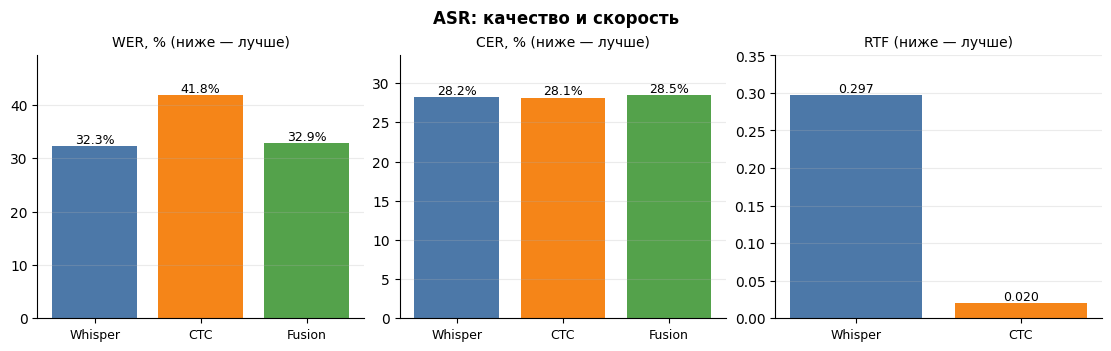

## 3. Диаризация

,Значение
Метрика,
DER (collar 0.25),20.4%
DER без overlap,11.7%
Пропуск речи,66.0 с (18.2%)
Ложная речь,5.7 с (1.6%)
Спутаны спикеры,2.2 с (0.6%)
Mapping score,0.842


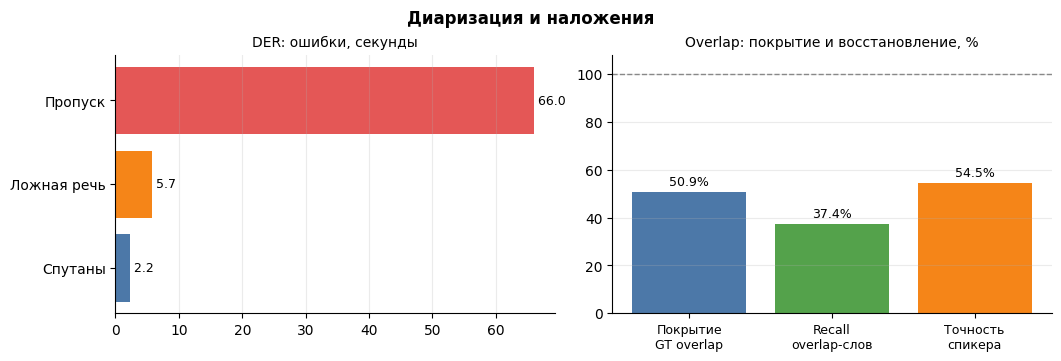

## 4. Наложения и separation

,Значение
Показатель,
GT overlap,52.8 с (12.6%)
Найдено overlap,33.1 с
Покрытие GT,50.9%
Max concurrent GT / hyp,4 / 3
Separation: островки / пропущено / слова,5 / 2 / 55
Recall overlap-слов,37.4% (99/265)
Speaker accuracy,54.5% (54/99)


## 5. Качество по спикерам

,WER,CER,Слов GT
Спикер,,,
FEE013,32.0%,27.0%,447
FEE016,32.9%,29.3%,298
MEE014,52.2%,47.4%,207
MEO015,41.4%,32.8%,162


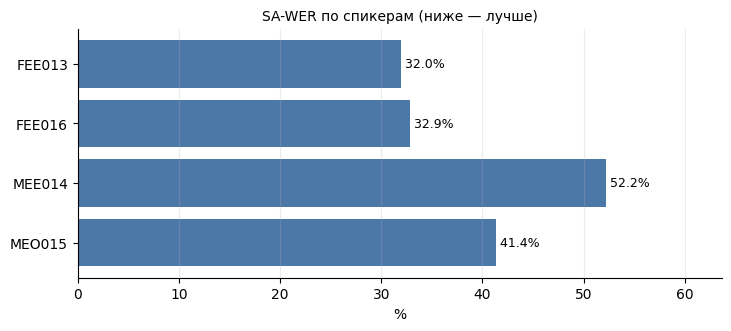

## 6. Выводы

- Whisper точнее CTC по WER на **9.5 п.п.**; по CER разрыв меньше: 28.1% против 28.2%.
- CTC быстрее в **14.8×** (RTF 0.020 против 0.297).
- Fusion меняет WER на **+0.5 п.п.** относительно Whisper, но формирует готовый транскрипт с именами.
- DER **20.4%**, без overlap — **11.7%**: главная ошибка — пропуск речи.
- Покрытие overlap **50.9%**, recovery **37.4%**, speaker accuracy **54.5%**.
- Худший спикер — `MEE014` с WER **52.2%**.
- Whisper — для качества и пунктуации; CTC — для скорости; separation — только для коротких островков с двумя спикерами.

In [15]:
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import pandas as pd

COLORS = ["#4C78A8", "#F58518", "#54A24B", "#E45756"]

def json_default(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    return str(o)

def valid_num(x):
    try:
        return x is not None and np.isfinite(float(x))
    except Exception:
        return False

def pct(x, digits=1):
    return f"{100 * float(x):.{digits}f}%" if valid_num(x) else "н/д"

def sec(x, digits=1):
    return f"{float(x):.{digits}f} с" if valid_num(x) else "н/д"

display(Markdown(f"# Результаты: AMI {MEETING}, окно {WINDOW[0]:.0f}–{WINDOW[1]:.0f} с"))

short = []
if WHISPER_METRICS:
    short.append(f"Whisper WER **{pct(WHISPER_METRICS.get('wer'))}**")
if CTC_METRICS:
    short.append(f"CTC WER **{pct(CTC_METRICS.get('wer'))}**")
if DIAR_METRICS and "der" in DIAR_METRICS:
    short.append(f"DER **{pct(DIAR_METRICS.get('der'))}**")
if valid_num(OVERLAP_COVERAGE):
    short.append(f"покрытие overlap **{pct(OVERLAP_COVERAGE)}**")
if short:
    display(Markdown(" · ".join(short)))

display(Markdown("## 1. Данные"))
display(pd.DataFrame([
    ("Окно", f"{WINDOW[0]:.0f}–{WINDOW[1]:.0f} с"),
    ("Спикеры", len(GT_SUMMARY.get("speakers_gt", []))),
    ("Речь GT", sec(GT_SPEECH_SEC)),
    ("Реплики / слова GT", f"{GT_SUMMARY.get('gt_turns', '—')} / {GT_SUMMARY.get('gt_words', '—')}"),
    ("Наложения GT", f"{sec(OVERLAP_SEC_GT)} ({pct(OVERLAP_RATIO_GT)})"),
    ("Max одновременных спикеров", MAX_CONCURRENT_GT),
], columns=["Параметр", "Значение"]).set_index("Параметр"))

display(Markdown("## 2. ASR"))
asr_labels = []
asr_wer, asr_cer, asr_rtf = [], [], []
if WHISPER_METRICS:
    asr_labels.append("Whisper")
    asr_wer.append(WHISPER_METRICS.get("wer"))
    asr_cer.append(WHISPER_METRICS.get("cer"))
    asr_rtf.append(WHISPER_TIMING.get("rtf"))
if CTC_METRICS:
    asr_labels.append("CTC")
    asr_wer.append(CTC_METRICS.get("wer"))
    asr_cer.append(CTC_METRICS.get("cer"))
    asr_rtf.append(CTC_TIMING.get("rtf"))
if FUSED_METRICS:
    asr_labels.append("Fusion")
    asr_wer.append(FUSED_METRICS.get("wer"))
    asr_cer.append(FUSED_METRICS.get("cer"))
    asr_rtf.append(np.nan)

def asr_time(timing):
    return sec(timing.get("elapsed_sec")) if timing else "—"

asr_rows = []
if WHISPER_METRICS:
    label = "Whisper " + str(WHISPER_TIMING.get("model", WHISPER_MODEL_NAME))
    if WHISPER_TIMING.get("device"):
        label += f" ({WHISPER_TIMING['device']})"
    asr_rows.append((label, pct(WHISPER_METRICS.get("wer")), pct(WHISPER_METRICS.get("cer")),
                     f"{WHISPER_TIMING.get('rtf', np.nan):.3f}", asr_time(WHISPER_TIMING)))
if CTC_METRICS:
    asr_rows.append(("CTC wav2vec2", pct(CTC_METRICS.get("wer")), pct(CTC_METRICS.get("cer")),
                     f"{CTC_TIMING.get('rtf', np.nan):.3f}", asr_time(CTC_TIMING)))
if FUSED_METRICS:
    asr_rows.append(("Fusion", pct(FUSED_METRICS.get("wer")), pct(FUSED_METRICS.get("cer")), "н/д", "—"))
display(pd.DataFrame(asr_rows, columns=["Модель", "WER", "CER", "RTF", "Время"]))

if asr_labels:
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), constrained_layout=True)
    specs = [
        ("WER", [100 * x if valid_num(x) else np.nan for x in asr_wer], "WER, % (ниже — лучше)", True),
        ("CER", [100 * x if valid_num(x) else np.nan for x in asr_cer], "CER, % (ниже — лучше)", True),
        ("RTF", [x if valid_num(x) else np.nan for x in asr_rtf], "RTF (ниже — лучше)", False),
    ]
    for ax, (_, vals, title, is_pct) in zip(axes, specs):
        bars = ax.bar(asr_labels, vals, color=COLORS[:len(asr_labels)])
        ax.set_title(title, fontsize=10)
        ax.grid(axis="y", alpha=0.25)
        ax.tick_params(axis="x", labelsize=9)
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)
        finite = [v for v in vals if valid_num(v)]
        if finite and max(finite) > 0:
            ax.set_ylim(0, max(finite) * 1.18)
        for bar, value in zip(bars, vals):
            if valid_num(value):
                label = f"{value:.1f}%" if is_pct else f"{value:.3f}"
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                        label, ha="center", va="bottom", fontsize=9)
    fig.suptitle("ASR: качество и скорость", fontsize=12, fontweight="bold")
    plt.show()

display(Markdown("## 3. Диаризация"))
comp = DIAR_METRICS.get("components", {}) if DIAR_METRICS else {}
if DIAR_METRICS and "der" in DIAR_METRICS:
    total = comp.get("total", 0.0) if comp else 0.0
    def share(key):
        return pct(comp.get(key, 0.0) / total) if valid_num(total) and total > 0 else "—"
    display(pd.DataFrame([
        ("DER (collar 0.25)", pct(DIAR_METRICS.get("der"))),
        ("DER без overlap", pct(DIAR_METRICS.get("der_skip_overlap"))),
        ("Пропуск речи", f"{sec(comp.get('missed detection'))} ({share('missed detection')})"),
        ("Ложная речь", f"{sec(comp.get('false alarm'))} ({share('false alarm')})"),
        ("Спутаны спикеры", f"{sec(comp.get('confusion'))} ({share('confusion')})"),
        ("Mapping score", f"{HYP2REF_SCORE:.3f}"),
    ], columns=["Метрика", "Значение"]).set_index("Метрика"))
else:
    display(Markdown(f"DER: н/д ({DIAR_METRICS.get('error', 'диаризация не выполнена')})"))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5), constrained_layout=True)
if comp:
    err_names = ["Пропуск", "Ложная речь", "Спутаны"]
    err_keys = ["missed detection", "false alarm", "confusion"]
    err_vals = [float(comp.get(k, 0.0)) for k in err_keys]
    bars = axes[0].barh(err_names, err_vals, color=["#E45756", "#F58518", "#4C78A8"])
    axes[0].invert_yaxis()
    axes[0].set_title("DER: ошибки, секунды", fontsize=10)
    axes[0].grid(axis="x", alpha=0.25)
    for bar, value in zip(bars, err_vals):
        axes[0].text(value, bar.get_y() + bar.get_height() / 2, f" {value:.1f}",
                     va="center", fontsize=9)
else:
    axes[0].text(0.5, 0.5, "DER: н/д", ha="center", va="center", transform=axes[0].transAxes)
    axes[0].set_axis_off()

ov_names = ["Покрытие\nGT overlap", "Recall\noverlap-слов", "Точность\nспикера"]
ov_vals = [
    100 * OVERLAP_COVERAGE if valid_num(OVERLAP_COVERAGE) else np.nan,
    100 * OVERLAP_RECOVERY.get("recall") if valid_num(OVERLAP_RECOVERY.get("recall")) else np.nan,
    100 * OVERLAP_RECOVERY.get("speaker_accuracy") if valid_num(OVERLAP_RECOVERY.get("speaker_accuracy")) else np.nan,
]
bars = axes[1].bar(ov_names, ov_vals, color=["#4C78A8", "#54A24B", "#F58518"])
axes[1].axhline(100, color="#888888", linestyle="--", linewidth=1)
axes[1].set_ylim(0, 108)
axes[1].set_title("Overlap: покрытие и восстановление, %", fontsize=10)
axes[1].grid(axis="y", alpha=0.25)
axes[1].tick_params(axis="x", labelsize=9)
for bar, value in zip(bars, ov_vals):
    if valid_num(value):
        axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
                     f"{value:.1f}%", ha="center", va="bottom", fontsize=9)
for ax in axes:
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
fig.suptitle("Диаризация и наложения", fontsize=12, fontweight="bold")
plt.show()

display(Markdown("## 4. Наложения и separation"))
overlap_rows = [
    ("GT overlap", f"{sec(OVERLAP_SEC_GT)} ({pct(OVERLAP_RATIO_GT)})"),
    ("Найдено overlap", sec(DET_SPEECH_SEC)),
    ("Покрытие GT", pct(OVERLAP_COVERAGE)),
    ("Max concurrent GT / hyp", f"{MAX_CONCURRENT_GT} / {MAX_CONCURRENT_DET}"),
    ("Separation: островки / пропущено / слова", f"{len(SEP_SELECTED)} / {len(SEP_SKIPPED)} / {len(SEP_WORDS)}"),
]
if valid_num(OVERLAP_RECOVERY.get("recall")):
    overlap_rows.append(("Recall overlap-слов",
                         f"{pct(OVERLAP_RECOVERY.get('recall'))} "
                         f"({OVERLAP_RECOVERY.get('matched')}/{OVERLAP_RECOVERY.get('ref_overlap_words')})"))
if valid_num(OVERLAP_RECOVERY.get("speaker_accuracy")):
    overlap_rows.append(("Speaker accuracy",
                         f"{pct(OVERLAP_RECOVERY.get('speaker_accuracy'))} "
                         f"({OVERLAP_RECOVERY.get('speaker_correct')}/{OVERLAP_RECOVERY.get('matched')})"))
display(pd.DataFrame(overlap_rows, columns=["Показатель", "Значение"]).set_index("Показатель"))

if SA_WER:
    display(Markdown("## 5. Качество по спикерам"))
    display(pd.DataFrame([
        (spk, pct(m.get("wer")), pct(m.get("cer")), m.get("ref_words", "—"))
        for spk, m in SA_WER.items()
    ], columns=["Спикер", "WER", "CER", "Слов GT"]).set_index("Спикер"))
    fig, ax = plt.subplots(figsize=(7.2, 3.2), constrained_layout=True)
    names = list(SA_WER)
    vals = [100 * SA_WER[n].get("wer", np.nan) for n in names]
    bars = ax.barh(names, vals, color="#4C78A8")
    ax.invert_yaxis()
    ax.set_title("SA-WER по спикерам (ниже — лучше)", fontsize=10)
    ax.set_xlabel("%")
    ax.grid(axis="x", alpha=0.25)
    finite = [v for v in vals if valid_num(v)]
    if finite and max(finite) > 0:
        ax.set_xlim(0, max(finite) * 1.22)
    for bar, value in zip(bars, vals):
        if valid_num(value):
            ax.text(value, bar.get_y() + bar.get_height() / 2, f" {value:.1f}%",
                    va="center", fontsize=9)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    plt.show()

display(Markdown("## 6. Выводы"))
conclusions = []
if WHISPER_METRICS and CTC_METRICS:
    delta = 100 * (CTC_METRICS.get("wer", 0) - WHISPER_METRICS.get("wer", 0))
    conclusions.append(f"Whisper точнее CTC по WER на **{abs(delta):.1f} п.п.**; "
                       f"по CER разрыв меньше: {pct(CTC_METRICS.get('cer'))} против {pct(WHISPER_METRICS.get('cer'))}.")
    if valid_num(WHISPER_TIMING.get("rtf")) and valid_num(CTC_TIMING.get("rtf")):
        conclusions.append(f"CTC быстрее в **{WHISPER_TIMING['rtf'] / CTC_TIMING['rtf']:.1f}×** "
                           f"(RTF {CTC_TIMING['rtf']:.3f} против {WHISPER_TIMING['rtf']:.3f}).")
if FUSED_METRICS and WHISPER_METRICS:
    delta = 100 * (FUSED_METRICS.get("wer", 0) - WHISPER_METRICS.get("wer", 0))
    conclusions.append(f"Fusion меняет WER на **{delta:+.1f} п.п.** относительно Whisper, "
                       "но формирует готовый транскрипт с именами.")
if DIAR_METRICS and "der" in DIAR_METRICS:
    conclusions.append(f"DER **{pct(DIAR_METRICS.get('der'))}**, без overlap — "
                       f"**{pct(DIAR_METRICS.get('der_skip_overlap'))}**: главная ошибка — пропуск речи.")
if valid_num(OVERLAP_COVERAGE) or valid_num(OVERLAP_RECOVERY.get("recall")):
    conclusions.append(f"Покрытие overlap **{pct(OVERLAP_COVERAGE)}**, recovery **{pct(OVERLAP_RECOVERY.get('recall'))}**, "
                       f"speaker accuracy **{pct(OVERLAP_RECOVERY.get('speaker_accuracy'))}**.")
if SA_WER:
    worst = max(SA_WER, key=lambda k: SA_WER[k].get("wer", 0))
    conclusions.append(f"Худший спикер — `{worst}` с WER **{pct(SA_WER[worst].get('wer'))}**.")
conclusions.append("Whisper — для качества и пунктуации; CTC — для скорости; separation — только "
                   "для коротких островков с двумя спикерами.")
display(Markdown("\n".join(f"- {x}" for x in conclusions)))





## 13. Синхронный перевод EN→RU с микрофона

Ниже — отдельный live-пайплайн, не меняющий предыдущие ячейки:

`микрофон → Silero VAD → streaming Whisper → Opus-MT → HTML-субтитры`

- Источник: только микрофон, 16 kHz mono.
- Live-модель: `faster-whisper small.en` на CPU; при нехватке скорости — `base.en`.
- Перевод: `Helsinki-NLP/opus-mt-en-ru`.
- Partial-субтитры обновляются примерно каждые 1.2 с; финальный перевод — после паузы.
- Benchmark прогоняет записанный с микрофона фрагмент через несколько ASR- и MT-моделей.

Запуск:

```python
run_live_translation(max_seconds=60)
run_benchmark()
```

`Ctrl+C` останавливает запись; поток микрофона закрывается в `finally`.

In [16]:
import os, time, queue, threading, gc, re, html
from pathlib import Path
from collections import OrderedDict

import numpy as np
import psutil
import torch
from IPython.display import display, Markdown
import ipywidgets as widgets

CACHE = Path(globals().get("CACHE", r"D:\speech_cache"))
CACHE.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("HF_HOME", str(CACHE / "hf"))
os.environ.setdefault("TORCH_HOME", str(CACHE / "torch"))
os.environ.setdefault("PIP_CACHE_DIR", str(CACHE / "pip"))

LIVE_SR = 16000
MIC_DEVICE = None
LIVE_SECONDS = 60
PARTIAL_EVERY = 1.2
ENDPOINT_SILENCE_MS = 450
MAX_UTTERANCE_SEC = 10.0

LIVE_ASR_NAME = "small.en"
LIVE_ASR_FALLBACK = "base.en"
LIVE_MT_NAME = "Helsinki-NLP/opus-mt-en-ru"

BENCH_ASR_NAMES = ["tiny.en", "base.en", "small.en", "medium.en"]
BENCH_MT_NAMES = [
    LIVE_MT_NAME,
    "Helsinki-NLP/opus-mt-tc-big-en-zle",
]
BIG_MT_PREFIX = ">>rus<<"

ASR_RAM_GB = {"tiny.en": 0.35, "base.en": 0.55, "small.en": 0.95, "medium.en": 1.8}
MT_RAM_GB = {LIVE_MT_NAME: 0.8, "Helsinki-NLP/opus-mt-tc-big-en-zle": 1.25}

LIVE_ASR_MODEL = None
LIVE_ASR_LOADED = None
LIVE_MT_TOKENIZER = None
LIVE_MT_MODEL = None
LIVE_AUDIO = None
LIVE_SEGMENTS = []


def free_old_models():
    """Освобождает модели из предыдущих ячеек, не трогая исходный код."""
    for name in ["WHISPER_MODEL", "ctc_model", "processor", "sep", "emb",
                 "ov_model", "pipeline", "diar_pipeline"]:
        obj = globals().pop(name, None)
        try:
            del obj
        except Exception:
            pass
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def show_env():
    import sounddevice as sd
    vm = psutil.virtual_memory()
    print(f"RAM available: {vm.available / 2**30:.2f} GiB / {vm.total / 2**30:.2f} GiB")
    print(f"HF cache: {CACHE}")
    try:
        info = sd.query_devices(kind="input")
        print(f"default mic: {info['name']} (index {info['index']})")
    except Exception as e:
        print("microphone error:", type(e).__name__, e)
    print("live ASR:", LIVE_ASR_NAME, "| fallback:", LIVE_ASR_FALLBACK)
    print("live MT:", LIVE_MT_NAME)

In [17]:
import sounddevice as sd


class AudioBuffer:
    """Кольцевой буфер на numpy: пишется из callback микрофона, читается из main loop."""

    def __init__(self, sr=LIVE_SR, max_seconds=180):
        self.sr = int(sr)
        self.buf = np.zeros(self.sr * int(max_seconds), dtype=np.float32)
        self.n = 0
        self.lock = threading.Lock()

    def write(self, x):
        x = np.asarray(x, dtype=np.float32).reshape(-1)
        with self.lock:
            m = min(len(x), len(self.buf) - self.n)
            if m > 0:
                self.buf[self.n:self.n + m] = x[:m]
                self.n += m

    def get(self, a, b):
        with self.lock:
            a = max(0, int(a))
            b = min(self.n, int(b))
            if b <= a:
                return np.zeros(0, dtype=np.float32)
            return self.buf[a:b].copy()

    def all(self):
        return self.get(0, self.n)

    def seconds(self):
        return self.n / self.sr


class MicrophoneStream:
    def __init__(self, device=None, sr=LIVE_SR, blocksize=512, audio=None):
        self.sr = int(sr)
        self.blocksize = int(blocksize)
        self.device = device if device is not None else sd.default.device[0]
        self.audio = audio if audio is not None else AudioBuffer(self.sr)
        self.q = queue.Queue()
        self.stream = None

    def _callback(self, indata, frames, time_info, status):
        if status:
            print("audio status:", status)
        x = np.asarray(indata[:, 0], dtype=np.float32).copy()
        self.audio.write(x)
        self.q.put(x)

    def __enter__(self):
        self.stream = sd.InputStream(
            device=self.device,
            channels=1,
            samplerate=self.sr,
            blocksize=self.blocksize,
            dtype="float32",
            callback=self._callback,
        )
        self.stream.start()
        info = sd.query_devices(self.device)
        print(f"microphone: {info['name']} (index {info['index']})")
        return self

    def __exit__(self, exc_type, exc, tb):
        if self.stream is not None:
            try:
                self.stream.stop()
            finally:
                self.stream.close()
        return False


class StreamingVAD:
    def __init__(self, threshold=0.5, min_silence_ms=ENDPOINT_SILENCE_MS, speech_pad_ms=150):
        from silero_vad import load_silero_vad, VADIterator
        self.model = load_silero_vad()
        self.it = VADIterator(
            self.model,
            threshold=float(threshold),
            sampling_rate=LIVE_SR,
            min_silence_duration_ms=int(min_silence_ms),
            speech_pad_ms=int(speech_pad_ms),
        )
        self.total = 0
        self.base = 0
        self.start = None

    def push(self, chunk):
        self.total += len(chunk)
        ev = self.it(torch.from_numpy(np.asarray(chunk, dtype=np.float32)), return_seconds=False)
        if not ev:
            return None
        if "start" in ev:
            self.start = int(ev["start"]) + self.base
            return ("start", self.start)
        if "end" in ev:
            end = int(ev["end"]) + self.base
            self.start = None
            return ("end", end)
        return None

    def reset(self):
        self.it.reset_states()
        self.base = self.total
        self.start = None


class SubtitleBoard:
    def __init__(self, max_rows=8):
        self.max_rows = int(max_rows)
        self.rows = OrderedDict()
        self.widget = widgets.HTML()
        display(self.widget)
        self.render()

    def set(self, uid, en, ru="", asr_ms=None, mt_ms=None, status="partial"):
        self.rows[uid] = {
            "en": en or "",
            "ru": ru or "",
            "asr_ms": asr_ms,
            "mt_ms": mt_ms,
            "status": status,
        }
        self.rows.move_to_end(uid)
        while len(self.rows) > self.max_rows:
            self.rows.popitem(last=False)
        self.render()

    def render(self):
        style = (
            "<style>"
            ".live-sub{font-family:Segoe UI,Arial,sans-serif;font-size:14px;border-collapse:collapse;width:100%}"
            ".live-sub th{background:#1f2937;color:white;padding:6px 8px;text-align:left}"
            ".live-sub td{border-bottom:1px solid #e5e7eb;padding:6px 8px;vertical-align:top}"
            ".live-sub td.en{color:#111827}"
            ".live-sub td.ru{color:#1d4ed8}"
            ".live-sub .meta{color:#6b7280;font-size:12px;white-space:nowrap}"
            "</style>"
        )
        if not self.rows:
            self.widget.value = style + "<div class='live-sub'><i>Ожидание речи...</i></div>"
            return
        body = []
        for uid, r in self.rows.items():
            color = "#15803d" if r["status"] == "final" else "#b45309"
            asr_ms = "—" if r["asr_ms"] is None else f"{r['asr_ms']:.0f}"
            mt_ms = "—" if r["mt_ms"] is None else f"{r['mt_ms']:.0f}"
            body.append(
                "<tr>"
                f"<td class='meta'>{html.escape(str(uid))}</td>"
                f"<td class='en'>{html.escape(r['en'])}</td>"
                f"<td class='ru'>{html.escape(r['ru']) or '<i>перевод...</i>'}</td>"
                f"<td class='meta' style='color:{color}'>{r['status']}</td>"
                f"<td class='meta'>ASR {asr_ms} ms<br>MT {mt_ms} ms</td>"
                "</tr>"
            )
        self.widget.value = (
            style
            + "<table class='live-sub'><thead><tr><th>#</th><th>English</th>"
              "<th>Русский</th><th>Статус</th><th>Задержка</th></tr></thead><tbody>"
            + "".join(body)
            + "</tbody></table>"
        )


def _norm_words(text):
    return re.findall(r"[a-z0-9']+", (text or "").lower())


def _lcp(a, b):
    n = 0
    for x, y in zip(a, b):
        if x != y:
            break
        n += 1
    return n


def load_whisper_model(name):
    from faster_whisper import WhisperModel
    t0 = time.perf_counter()
    model = WhisperModel(name, device="cpu", compute_type="int8",
                         cpu_threads=min(8, os.cpu_count() or 4))
    return model, time.perf_counter() - t0


def transcribe_text(model, audio, beam_size=1):
    if model is None or audio is None or len(audio) < int(0.2 * LIVE_SR):
        return ""
    audio = np.ascontiguousarray(audio, dtype=np.float32)
    segments, info = model.transcribe(
        audio,
        language="en",
        beam_size=int(beam_size),
        temperature=0.0,
        vad_filter=False,
        condition_on_previous_text=False,
        without_timestamps=True,
    )
    return " ".join(s.text.strip() for s in segments).strip()


def load_mt_model(name):
    from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
    t0 = time.perf_counter()
    tok = AutoTokenizer.from_pretrained(name, cache_dir=str(CACHE / "hf"))
    model = AutoModelForSeq2SeqLM.from_pretrained(
        name, cache_dir=str(CACHE / "hf"), low_cpu_mem_usage=True
    ).to("cpu").eval()
    return tok, model, time.perf_counter() - t0


def _split_sentences(text):
    parts = re.split(r"(?<=[.!?])\s+", (text or "").strip())
    return [p.strip() for p in parts if p.strip()]


def translate_texts(tok, model, texts, prefix="", num_beams=4, max_new_tokens=256):
    if not texts:
        return []
    flat, owner = [], []
    for i, text in enumerate(texts):
        parts = _split_sentences(text) or [text]
        for part in parts:
            flat.append(prefix + part)
            owner.append(i)
    enc = tok(flat, return_tensors="pt", padding=True, truncation=True, max_length=512)
    with torch.inference_mode():
        out = model.generate(
            **enc,
            max_new_tokens=int(max_new_tokens),
            num_beams=int(num_beams),
            no_repeat_ngram_size=3,
        )
    decoded = tok.batch_decode(out, skip_special_tokens=True)
    grouped = [[] for _ in texts]
    for i, ru in zip(owner, decoded):
        grouped[i].append(ru.strip())
    return [" ".join(x).strip() for x in grouped]

def test_microphone(seconds=3):
    buf = AudioBuffer(max_seconds=max(10, int(seconds) + 5))
    with MicrophoneStream(audio=buf) as mic:
        time.sleep(float(seconds))
    x = buf.all()
    if len(x) == 0:
        print("no audio")
        return
    rms = float(np.sqrt(np.mean(x ** 2)))
    peak = float(np.max(np.abs(x)))
    print(f"samples={len(x)} duration={len(x)/LIVE_SR:.2f}s rms={rms:.4f} peak={peak:.4f}")

In [18]:
def run_live_translation(max_seconds=LIVE_SECONDS, device=MIC_DEVICE,
                         partial_every=PARTIAL_EVERY, max_utterance=MAX_UTTERANCE_SEC):
    global LIVE_ASR_MODEL, LIVE_ASR_LOADED, LIVE_MT_TOKENIZER, LIVE_MT_MODEL
    global LIVE_AUDIO, LIVE_SEGMENTS

    free_old_models()
    print(f"RAM before live: {psutil.virtual_memory().available / 2**30:.2f} GiB")
    board = SubtitleBoard()
    audio = AudioBuffer(max_seconds=max(60, int(max_seconds) + 20))

    asr_model = None
    asr_name = None
    for name in [LIVE_ASR_NAME, LIVE_ASR_FALLBACK]:
        try:
            print(f"loading ASR: {name}")
            asr_model, load_s = load_whisper_model(name)
            asr_name = name
            print(f"ASR loaded in {load_s:.1f}s")
            if name == LIVE_ASR_NAME:
                warm = np.zeros(int(LIVE_SR * 2.0), dtype=np.float32)
                t_w = time.perf_counter()
                _ = transcribe_text(asr_model, warm, beam_size=1)
                warm_s = time.perf_counter() - t_w
                print(f"small.en warmup partial latency: {warm_s:.2f}s")
                if warm_s > 1.6:
                    print("small.en slow for partial updates; switching to base.en")
                    del asr_model
                    asr_model = None
                    gc.collect()
                    continue
            break
        except Exception as e:
            print("ASR failed:", name, type(e).__name__, str(e)[:200])
            asr_model = None
            gc.collect()
    if asr_model is None:
        raise RuntimeError("Whisper не загрузился")

    print(f"loading MT: {LIVE_MT_NAME}")
    mt_tok, mt_model, mt_load_s = load_mt_model(LIVE_MT_NAME)
    print(f"MT loaded in {mt_load_s:.1f}s")

    vad = StreamingVAD()
    segments = []
    uid_counter = 0
    current_uid = None
    start = None
    prev_tokens = []
    last_en = ""
    last_ru = ""
    last_partial = 0.0

    def finalize_segment(a, b, uid):
        seg = audio.get(a, b)
        if len(seg) < int(0.25 * LIVE_SR):
            return
        t0 = time.perf_counter()
        text = transcribe_text(asr_model, seg, beam_size=5)
        asr_ms = 1000 * (time.perf_counter() - t0)
        if not text:
            return
        t1 = time.perf_counter()
        ru = translate_texts(mt_tok, mt_model, [text], num_beams=4, max_new_tokens=256)[0]
        mt_ms = 1000 * (time.perf_counter() - t1)
        rec = {"start": a / LIVE_SR, "end": b / LIVE_SR,
               "text": text, "ru": ru, "asr_ms": asr_ms, "mt_ms": mt_ms}
        segments.append(rec)
        board.set(uid, text, ru, asr_ms, mt_ms, "final")
        print(f"[{a/LIVE_SR:6.1f}-{b/LIVE_SR:6.1f}] {text} -> {ru}")

    try:
        with MicrophoneStream(device=device, audio=audio) as mic:
            print(f"recording up to {max_seconds}s; Ctrl+C to stop")
            t_start = time.time()
            while time.time() - t_start < max_seconds:
                try:
                    chunk = mic.q.get(timeout=0.2)
                except queue.Empty:
                    continue

                ev = vad.push(chunk)
                now = time.time()

                if ev is not None:
                    kind, pos = ev
                    if kind == "start":
                        start = max(0, int(pos))
                        current_uid = f"u{uid_counter}"
                        uid_counter += 1
                        prev_tokens = []
                        last_en = ""
                        last_ru = ""
                        last_partial = 0.0
                    elif kind == "end" and start is not None:
                        end = max(int(pos), start + int(0.1 * LIVE_SR))
                        finalize_segment(start, end, current_uid)
                        start = None
                        current_uid = None
                        prev_tokens = []
                        last_en = ""
                        last_ru = ""

                if start is None:
                    continue

                spoken = audio.n - start
                if spoken >= int(max_utterance * LIVE_SR):
                    finalize_segment(start, audio.n, current_uid)
                    start = None
                    current_uid = None
                    vad.reset()
                    continue

                if (now - last_partial >= partial_every
                        and spoken >= int(0.8 * LIVE_SR)
                        and mic.q.qsize() < 16):
                    cur = audio.get(start, audio.n)
                    t0 = time.perf_counter()
                    text = transcribe_text(asr_model, cur, beam_size=1)
                    asr_ms = 1000 * (time.perf_counter() - t0)
                    last_partial = now
                    if not text:
                        continue

                    toks = text.split()
                    ntoks = [_norm_words(t) for t in toks]
                    stable_n = _lcp(prev_tokens, ntoks) if prev_tokens else max(0, len(ntoks) - 2)
                    prev_tokens = ntoks
                    stable = " ".join(toks[:stable_n]).strip()

                    if stable_n >= 2 and stable and stable != last_en:
                        t1 = time.perf_counter()
                        ru = translate_texts(
                            mt_tok, mt_model, [stable], num_beams=1, max_new_tokens=128
                        )[0]
                        mt_ms = 1000 * (time.perf_counter() - t1)
                        last_en = stable
                        last_ru = ru
                        board.set(current_uid, text, ru, asr_ms, mt_ms, "partial")
                    else:
                        board.set(current_uid, text, last_ru, asr_ms, 0.0, "partial")
    finally:
        if start is not None and current_uid is not None:
            try:
                finalize_segment(start, audio.n, current_uid)
            except Exception as e:
                print("finalize error:", type(e).__name__, e)

    LIVE_ASR_MODEL = asr_model
    LIVE_ASR_LOADED = asr_name
    LIVE_MT_TOKENIZER = mt_tok
    LIVE_MT_MODEL = mt_model
    LIVE_AUDIO = audio
    LIVE_SEGMENTS = segments
    print(f"done: {len(segments)} final segments, recorded {audio.seconds():.1f}s")
    return segments


def run_benchmark(audio=None, segments=None, asr_names=None, mt_names=None):
    import pandas as pd

    asr_names = list(asr_names or BENCH_ASR_NAMES)
    mt_names = list(mt_names or BENCH_MT_NAMES)
    if audio is None:
        audio = LIVE_AUDIO.all() if LIVE_AUDIO is not None else np.zeros(0, dtype=np.float32)
    audio = np.asarray(audio, dtype=np.float32).reshape(-1)
    if len(audio) < LIVE_SR:
        print("Нет записанного аудио: сначала запусти run_live_translation().")
        return None

    if segments is None:
        segments = LIVE_SEGMENTS
    texts = [s.get("text", "").strip() for s in (segments or []) if s.get("text", "").strip()]
    duration = len(audio) / LIVE_SR

    for var in ["LIVE_ASR_MODEL", "LIVE_MT_MODEL"]:
        obj = globals().pop(var, None)
        try:
            del obj
        except Exception:
            pass
    gc.collect()

    print(f"benchmark audio: {duration:.1f}s; reference translations: {len(texts)}")
    display(Markdown("### ASR benchmark"))

    asr_rows = []
    for name in asr_names:
        avail = psutil.virtual_memory().available / 2**30
        need = ASR_RAM_GB.get(name, 1.0)
        if avail < need * 0.9:
            asr_rows.append({"model": name, "load_s": None, "latency_s": None,
                             "RTF": None, "text": "", "note": f"skip: RAM {avail:.2f} < {need:.2f} GiB"})
            continue
        model = None
        try:
            model, load_s = load_whisper_model(name)
            t0 = time.perf_counter()
            text = transcribe_text(model, audio, beam_size=5)
            elapsed = time.perf_counter() - t0
            asr_rows.append({"model": name, "load_s": round(load_s, 2),
                             "latency_s": round(elapsed, 2),
                             "RTF": round(elapsed / max(duration, 1e-9), 3),
                             "text": text[:240], "note": ""})
        except Exception as e:
            asr_rows.append({"model": name, "load_s": None, "latency_s": None,
                             "RTF": None, "text": "", "note": f"{type(e).__name__}: {str(e)[:120]}"})
        finally:
            del model
            gc.collect()

    display(pd.DataFrame(asr_rows))

    if not texts:
        texts = [r["text"] for r in asr_rows if r.get("text")][:4]
    if not texts:
        print("MT benchmark пропущен: нет текста для перевода.")
        return {"asr": asr_rows, "mt": []}

    display(Markdown("### MT benchmark"))
    mt_rows = []
    mt_outputs = {}
    for name in mt_names:
        avail = psutil.virtual_memory().available / 2**30
        need = MT_RAM_GB.get(name, 1.0)
        if avail < need * 0.9:
            mt_rows.append({"model": name, "load_s": None, "latency_s": None,
                            "chars_per_s": None, "first_ru": "",
                            "note": f"skip: RAM {avail:.2f} < {need:.2f} GiB"})
            continue
        tok = model = None
        try:
            tok, model, load_s = load_mt_model(name)
            prefix = BIG_MT_PREFIX if name.endswith("en-zle") else ""
            t0 = time.perf_counter()
            outs = translate_texts(tok, model, texts[:4], prefix=prefix,
                                   num_beams=4, max_new_tokens=256)
            elapsed = time.perf_counter() - t0
            chars = sum(len(t) for t in texts[:4])
            mt_outputs[name] = outs
            mt_rows.append({"model": name, "load_s": round(load_s, 2),
                            "latency_s": round(elapsed, 2),
                            "chars_per_s": round(chars / max(elapsed, 1e-9), 1),
                            "first_ru": outs[0] if outs else "", "note": ""})
        except Exception as e:
            mt_rows.append({"model": name, "load_s": None, "latency_s": None,
                            "chars_per_s": None, "first_ru": "",
                            "note": f"{type(e).__name__}: {str(e)[:120]}"})
        finally:
            del tok, model
            gc.collect()

    display(pd.DataFrame(mt_rows))

    if mt_outputs:
        n = min(4, len(texts))
        side = []
        for i in range(n):
            row = {"English": texts[i]}
            for name, outs in mt_outputs.items():
                row[name] = outs[i] if i < len(outs) else ""
            side.append(row)
        display(Markdown("### Переводы side-by-side"))
        display(pd.DataFrame(side))

    return {"asr": asr_rows, "mt": mt_rows}

In [23]:
show_env()

# 1) Проверка микрофона (3 секунды):
#test_microphone(3)

# 2) Live-субтитры (остановка: max_seconds или Ctrl+C):
run_live_translation(max_seconds=60)



RAM available: 1.56 GiB / 13.86 GiB
HF cache: D:\speech_cache
default mic: Набор микрофонов (Realtek(R) Au (index 1)
live ASR: small.en | fallback: base.en
live MT: Helsinki-NLP/opus-mt-en-ru
RAM before live: 1.57 GiB


HTML(value='')

loading ASR: small.en
ASR loaded in 1.5s
small.en warmup partial latency: 2.20s
small.en slow for partial updates; switching to base.en
loading ASR: base.en
ASR loaded in 0.6s
loading MT: Helsinki-NLP/opus-mt-en-ru


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie model.shared.weight to model.decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


MT loaded in 3.0s
microphone: Набор микрофонов (Realtek(R) Au (index 1)
recording up to 60s; Ctrl+C to stop


... (31 outputs left out)

[  50.5-  53.8] Hold your hips up like... -> Подними бедра, как...


Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[  54.2-  60.0] and it won't be afraid of the dark at the end of the -> И он не будет бояться темноты в конце
done: 17 final segments, recorded 60.0s


[{'start': 2.794,
  'end': 4.214,
  'text': 'When you',
  'ru': 'Когда ты',
  'asr_ms': 751.4579000417143,
  'mt_ms': 300.9662000113167},
 {'start': 6.666,
  'end': 8.022,
  'text': 'of this storm.',
  'ru': 'Этого шторма.',
  'asr_ms': 685.3714000317268,
  'mt_ms': 330.2197000011802},
 {'start': 8.362,
  'end': 9.782,
  'text': 'Hold your head.',
  'ru': 'Держи голову.',
  'asr_ms': 834.3829000368714,
  'mt_ms': 327.04339997144416},
 {'start': 10.154,
  'end': 11.83,
  'text': 'Up high.',
  'ru': 'Вверх.',
  'asr_ms': 694.5986000355333,
  'mt_ms': 328.7437000544742},
 {'start': 12.586,
  'end': 17.174,
  'text': "and don't be afraid of the dark.",
  'ru': 'И не бойтесь темноты.',
  'asr_ms': 750.2240999601781,
  'mt_ms': 507.27460003690794},
 {'start': 17.642,
  'end': 20.374,
  'text': 'at the end of the storm.',
  'ru': 'в конце шторма.',
  'asr_ms': 812.8347999881953,
  'mt_ms': 363.1790999788791},
 {'start': 21.194,
  'end': 23.638,
  'text': 'Vehicle, then sky',
  'ru': 'Автомоби

In [24]:
# 3) Benchmark на записанном фрагменте:
run_benchmark()

benchmark audio: 60.0s; reference translations: 17


### ASR benchmark

,model,load_s,latency_s,RTF,text,note
0,tiny.en,0.55,1.27,0.021,"When you walk through the storm, hold your hea...",
1,base.en,0.57,1.87,0.031,"When you walk through the storm, hold your hea...",
2,small.en,1.42,6.74,0.112,"When you walk through the storm, hold your hea...",
3,medium.en,NaN,NaN,NaN,,skip: RAM 1.23 < 1.80 GiB


### MT benchmark

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie model.shared.weight to model.decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


... (2 outputs left out)

,model,load_s,latency_s,chars_per_s,first_ru,note
0,Helsinki-NLP/opus-mt-en-ru,3.11,0.51,87.6,Когда ты,
1,Helsinki-NLP/opus-mt-tc-big-en-zle,5.09,1.52,29.5,Когда вы,


### Переводы side-by-side

,English,Helsinki-NLP/opus-mt-en-ru,Helsinki-NLP/opus-mt-tc-big-en-zle
0,When you,Когда ты,Когда вы
1,of this storm.,Этого шторма.,этого шторма.
2,Hold your head.,Держи голову.,Держи голову.
3,Up high.,Вверх.,Наверху.


{'asr': [{'model': 'tiny.en',
   'load_s': 0.55,
   'latency_s': 1.27,
   'RTF': 0.021,
   'text': "When you walk through the storm, hold your head up high, and don't be afraid of the dark at the end of the storm. come through the wind, walk home through the rain, show your dreams, be toast and gone, walk home, walk home through the storm",
   'note': ''},
  {'model': 'base.en',
   'load_s': 0.57,
   'latency_s': 1.87,
   'RTF': 0.031,
   'text': "When you walk through the storm, hold your head up high and don't be afraid of the dark at the end of the storm. The golden sky and a sweet silo song of a lark. through the rain.",
   'note': ''},
  {'model': 'small.en',
   'load_s': 1.42,
   'latency_s': 6.74,
   'RTF': 0.112,
   'text': "When you walk through the storm, hold your head up high and don't be afraid of the dark at the end of the storm. The golden sky and the sweet silver sun of a lark. walk on through the wind, walk on through the rain, show your dreams, be toa",
   'note': ''}